In [2]:
import wfdb
import numpy as np
import matplotlib.pyplot as plt
import pywt

record_path = (
    r"E:\MIMIC4\MIMIC4\physionet.org\files\mimic4wdb\0.1.0"
    r"\waves\p100\p10014354\81739927\81739927_0008"
)

fs = 62.4725
start_sec = 10
duration_sec = 8
end_sec = start_sec + duration_sec

start_sample = int(start_sec * fs)
end_sample = int(end_sec * fs)

record = wfdb.rdrecord(
    record_path,
    sampfrom=start_sample,
    sampto=end_sample
)

ecg = record.p_signal[:, record.sig_name.index("II")]
ppg = record.p_signal[:, record.sig_name.index("Pleth")]

time = np.arange(len(ecg)) / fs + start_sec

print("Record ID:", record_path.split("\\")[-1])
print("ECG samples:", len(ecg))
print("PPG samples:", len(ppg))
print("Sampling frequency:", fs, "Hz")
print("Duration:", len(ecg) / fs, "seconds")

Record ID: 81739927_0008
ECG samples: 500
PPG samples: 500
Sampling frequency: 62.4725 Hz
Duration: 8.003521549481773 seconds


In [3]:
from pathlib import Path

waves_root = Path(
    r"E:\MIMIC4\MIMIC4\physionet.org\files\mimic4wdb\0.1.0\waves"
)

record_ids = [
    "81739927_0008",
    "81739927_0010",
    "81739927_0014",
    "81739927_0016",
    "81739927_0017",
    "81739927_0020",
    "87033314_0007",
    "87033314_0008",
    "83404654_0001",
    "83404654_0004"
]

# Har record ki .hea file locate karo
record_paths = {}

for hea_file in waves_root.rglob("*.hea"):
    record_id = hea_file.stem

    if record_id in record_ids:
        record_paths[record_id] = hea_file.with_suffix("")

print("Records found:", len(record_paths))

for record_id in record_ids:
    print(record_id, "->", record_paths.get(record_id, "NOT FOUND"))

Records found: 10
81739927_0008 -> E:\MIMIC4\MIMIC4\physionet.org\files\mimic4wdb\0.1.0\waves\p100\p10014354\81739927\81739927_0008
81739927_0010 -> E:\MIMIC4\MIMIC4\physionet.org\files\mimic4wdb\0.1.0\waves\p100\p10014354\81739927\81739927_0010
81739927_0014 -> E:\MIMIC4\MIMIC4\physionet.org\files\mimic4wdb\0.1.0\waves\p100\p10014354\81739927\81739927_0014
81739927_0016 -> E:\MIMIC4\MIMIC4\physionet.org\files\mimic4wdb\0.1.0\waves\p100\p10014354\81739927\81739927_0016
81739927_0017 -> E:\MIMIC4\MIMIC4\physionet.org\files\mimic4wdb\0.1.0\waves\p100\p10014354\81739927\81739927_0017
81739927_0020 -> E:\MIMIC4\MIMIC4\physionet.org\files\mimic4wdb\0.1.0\waves\p100\p10014354\81739927\81739927_0020
87033314_0007 -> E:\MIMIC4\MIMIC4\physionet.org\files\mimic4wdb\0.1.0\waves\p100\p10019003\87033314\87033314_0007
87033314_0008 -> E:\MIMIC4\MIMIC4\physionet.org\files\mimic4wdb\0.1.0\waves\p100\p10019003\87033314\87033314_0008
83404654_0001 -> E:\MIMIC4\MIMIC4\physionet.org\files\mimic4wdb\0.1.0\

In [4]:
loaded_records = {}

fs_expected = 62.4725
start_sec = 10
duration_sec = 8

for record_id in record_ids:

    if record_id not in record_paths:
        print(f"Skipping {record_id}: path not found")
        continue

    try:
        record = wfdb.rdrecord(
            str(record_paths[record_id]),
            sampfrom=int(start_sec * fs_expected),
            sampto=int((start_sec + duration_sec) * fs_expected)
        )

        if "II" not in record.sig_name or "Pleth" not in record.sig_name:
            print(f"Skipping {record_id}: ECG II or Pleth missing")
            continue

        fs_record = record.fs

        ecg_segment = record.p_signal[
            :, record.sig_name.index("II")
        ]

        ppg_segment = record.p_signal[
            :, record.sig_name.index("Pleth")
        ]

        if (
            len(ecg_segment) != len(ppg_segment)
            or len(ecg_segment) < 2
            or not np.isfinite(ecg_segment).all()
            or not np.isfinite(ppg_segment).all()
        ):
            print(f"Skipping {record_id}: invalid segment")
            continue

        loaded_records[record_id] = {
            "ecg": ecg_segment,
            "ppg": ppg_segment,
            "fs": fs_record
        }

        print(
            f"{record_id}: loaded successfully | "
            f"samples={len(ecg_segment)} | fs={fs_record}"
        )

    except Exception as e:
        print(f"{record_id}: loading failed: {e}")

print("\nTotal records loaded:", len(loaded_records))

81739927_0008: loaded successfully | samples=500 | fs=62.4725
81739927_0010: loaded successfully | samples=500 | fs=62.4725
81739927_0014: loaded successfully | samples=500 | fs=62.4725
81739927_0016: loaded successfully | samples=500 | fs=62.4725
81739927_0017: loaded successfully | samples=500 | fs=62.4725
81739927_0020: loaded successfully | samples=500 | fs=62.4725
87033314_0007: loaded successfully | samples=500 | fs=62.4725
87033314_0008: loaded successfully | samples=500 | fs=62.4725
83404654_0001: loaded successfully | samples=500 | fs=62.4725
83404654_0004: loaded successfully | samples=500 | fs=62.4725

Total records loaded: 10


In [5]:
import pandas as pd

energy_results = []

for record_id, signals in loaded_records.items():

    ecg_signal = signals["ecg"]

    coeffs = pywt.wavedec(
        ecg_signal,
        "haar",
        level=3
    )

    # wavedec order: [A3, D3, D2, D1]
    cA3, cD3, cD2, cD1 = coeffs

    energies = {
        "D1": np.sum(cD1 ** 2),
        "D2": np.sum(cD2 ** 2),
        "D3": np.sum(cD3 ** 2),
        "A3": np.sum(cA3 ** 2)
    }

    total_energy = sum(energies.values())

    row = {"Record_ID": record_id}

    for component, energy in energies.items():
        row[f"{component}_Energy"] = energy
        row[f"{component}_Relative_Percent"] = (
            100 * energy / total_energy
            if total_energy > 0 else np.nan
        )

    energy_results.append(row)

energy_df = pd.DataFrame(energy_results)

display(energy_df.round(4))

,Record_ID,D1_Energy,D1_Relative_Percent,D2_Energy,D2_Relative_Percent,D3_Energy,D3_Relative_Percent,A3_Energy,A3_Relative_Percent
0,81739927_0008,1.7067,13.4113,5.1318,40.3265,1.3762,10.8141,4.5110,35.4481
1,81739927_0010,1.0834,18.1828,1.1927,20.0187,1.5120,25.3771,2.1700,36.4213
2,81739927_0014,628.3316,8.3179,2233.9394,29.5732,1006.2485,13.3209,3685.4069,48.7880
3,81739927_0016,0.9619,11.5711,1.2205,14.6827,1.8204,21.8993,4.3099,51.8469
4,81739927_0017,1.0772,7.9688,1.9329,14.2992,2.7880,20.6254,7.7193,57.1065
5,81739927_0020,1.8886,9.2185,1.7993,8.7827,2.7194,13.2741,14.0794,68.7246
6,87033314_0007,1.3612,18.5096,2.4464,33.2666,1.5743,21.4079,1.9720,26.8158
7,87033314_0008,1.8558,31.5529,1.6250,27.6288,1.0224,17.3827,1.3784,23.4356
8,83404654_0001,0.5369,1.8340,1.5960,5.4521,2.1913,7.4855,24.9491,85.2284
9,83404654_0004,0.5282,10.3149,1.2825,25.0452,1.3270,25.9135,1.9831,38.7265


In [6]:
import numpy as np
import pandas as pd
import pywt

bayes_results = []

for record_id, signals in loaded_records.items():

    # 1. Current record ka ECG
    ecg_original = signals["ecg"]
    
    # 2. Haar DWT decomposition, level 3
    coeffs = pywt.wavedec(
        ecg_original,
        "haar",
        level=3
    )

    # 3. Finest detail coefficients se noise estimate
    sigma = np.median(np.abs(coeffs[-1])) / 0.6745
    noise_var = sigma ** 2

    # 4. Har detail level ka BayesShrink threshold
    bayes_thresholds = []

    for detail in coeffs[1:]:
        signal_var = max(np.var(detail) - noise_var, 0)

        if signal_var == 0:
            threshold_bayes = np.max(np.abs(detail))
        else:
            threshold_bayes = noise_var / np.sqrt(signal_var)

        bayes_thresholds.append(threshold_bayes)

    # 5. Soft thresholding
    coeffs_bayes = [coeffs[0]]

    for detail, thr in zip(coeffs[1:], bayes_thresholds):
        coeffs_bayes.append(
            pywt.threshold(detail, thr, mode="soft")
        )

    # 6. Reconstruct denoised ECG
    ecg_bayes = pywt.waverec(coeffs_bayes, "haar")

    # Ensure reconstructed length matches original
    ecg_bayes = ecg_bayes[:len(ecg_original)]

    # 7. Evaluation metrics
    error = ecg_original - ecg_bayes

    rmse = np.sqrt(np.mean(error ** 2))
    mae = np.mean(np.abs(error))

    signal_range = np.max(ecg_original) - np.min(ecg_original)
    nrmse = rmse / signal_range if signal_range > 0 else np.nan

    signal_energy = np.sum(ecg_original ** 2)
    prd = (
        100 * np.sqrt(np.sum(error ** 2) / signal_energy)
        if signal_energy > 0 else np.nan
    )

    if np.std(ecg_original) > 0 and np.std(ecg_bayes) > 0:
        correlation = np.corrcoef(ecg_original, ecg_bayes)[0, 1]
    else:
        correlation = np.nan

    # 8. Store results
    bayes_results.append({
        "Record_ID": record_id,
        "Noise_Sigma": sigma,
        "D1_Threshold": bayes_thresholds[-1],
        "D2_Threshold": bayes_thresholds[-2],
        "D3_Threshold": bayes_thresholds[-3],
        "RMSE": rmse,
        "MAE": mae,
        "NRMSE": nrmse,
        "PRD_Percent": prd,
        "Correlation": correlation
    })

# 9. Display comparison table
bayes_df = pd.DataFrame(bayes_results)

display(bayes_df.round(6))

,Record_ID,Noise_Sigma,D1_Threshold,D2_Threshold,D3_Threshold,RMSE,MAE,NRMSE,PRD_Percent,Correlation
0,81739927_0008,0.031450,0.012961,0.005217,0.006860,0.008493,0.007557,0.009282,5.340152,0.998753
1,81739927_0010,0.015725,0.003868,0.002565,0.001607,0.002958,0.002615,0.003842,2.714406,0.999687
2,81739927_0014,0.015725,0.000156,0.000059,0.000062,0.000099,0.000080,0.000002,0.002535,1.000000
3,81739927_0016,0.026209,0.012218,0.007219,0.004090,0.008554,0.007557,0.010966,6.635845,0.997987
4,81739927_0017,0.020967,0.007071,0.003593,0.002101,0.004836,0.004330,0.003980,2.942692,0.999590
5,81739927_0020,0.041934,0.023105,0.015654,0.008645,0.015919,0.013538,0.008227,7.864361,0.997105
6,87033314_0007,0.015725,0.003430,0.001782,0.001573,0.002509,0.002265,0.002281,2.082112,0.999808
7,87033314_0008,0.020967,0.005263,0.003943,0.003499,0.004108,0.003485,0.004393,3.830398,0.999411
8,83404654_0001,0.015725,0.005678,0.002212,0.001331,0.003803,0.003511,0.002355,1.574693,0.999877
9,83404654_0004,0.010483,0.002456,0.001092,0.000760,0.001683,0.001530,0.002028,1.663455,0.999850


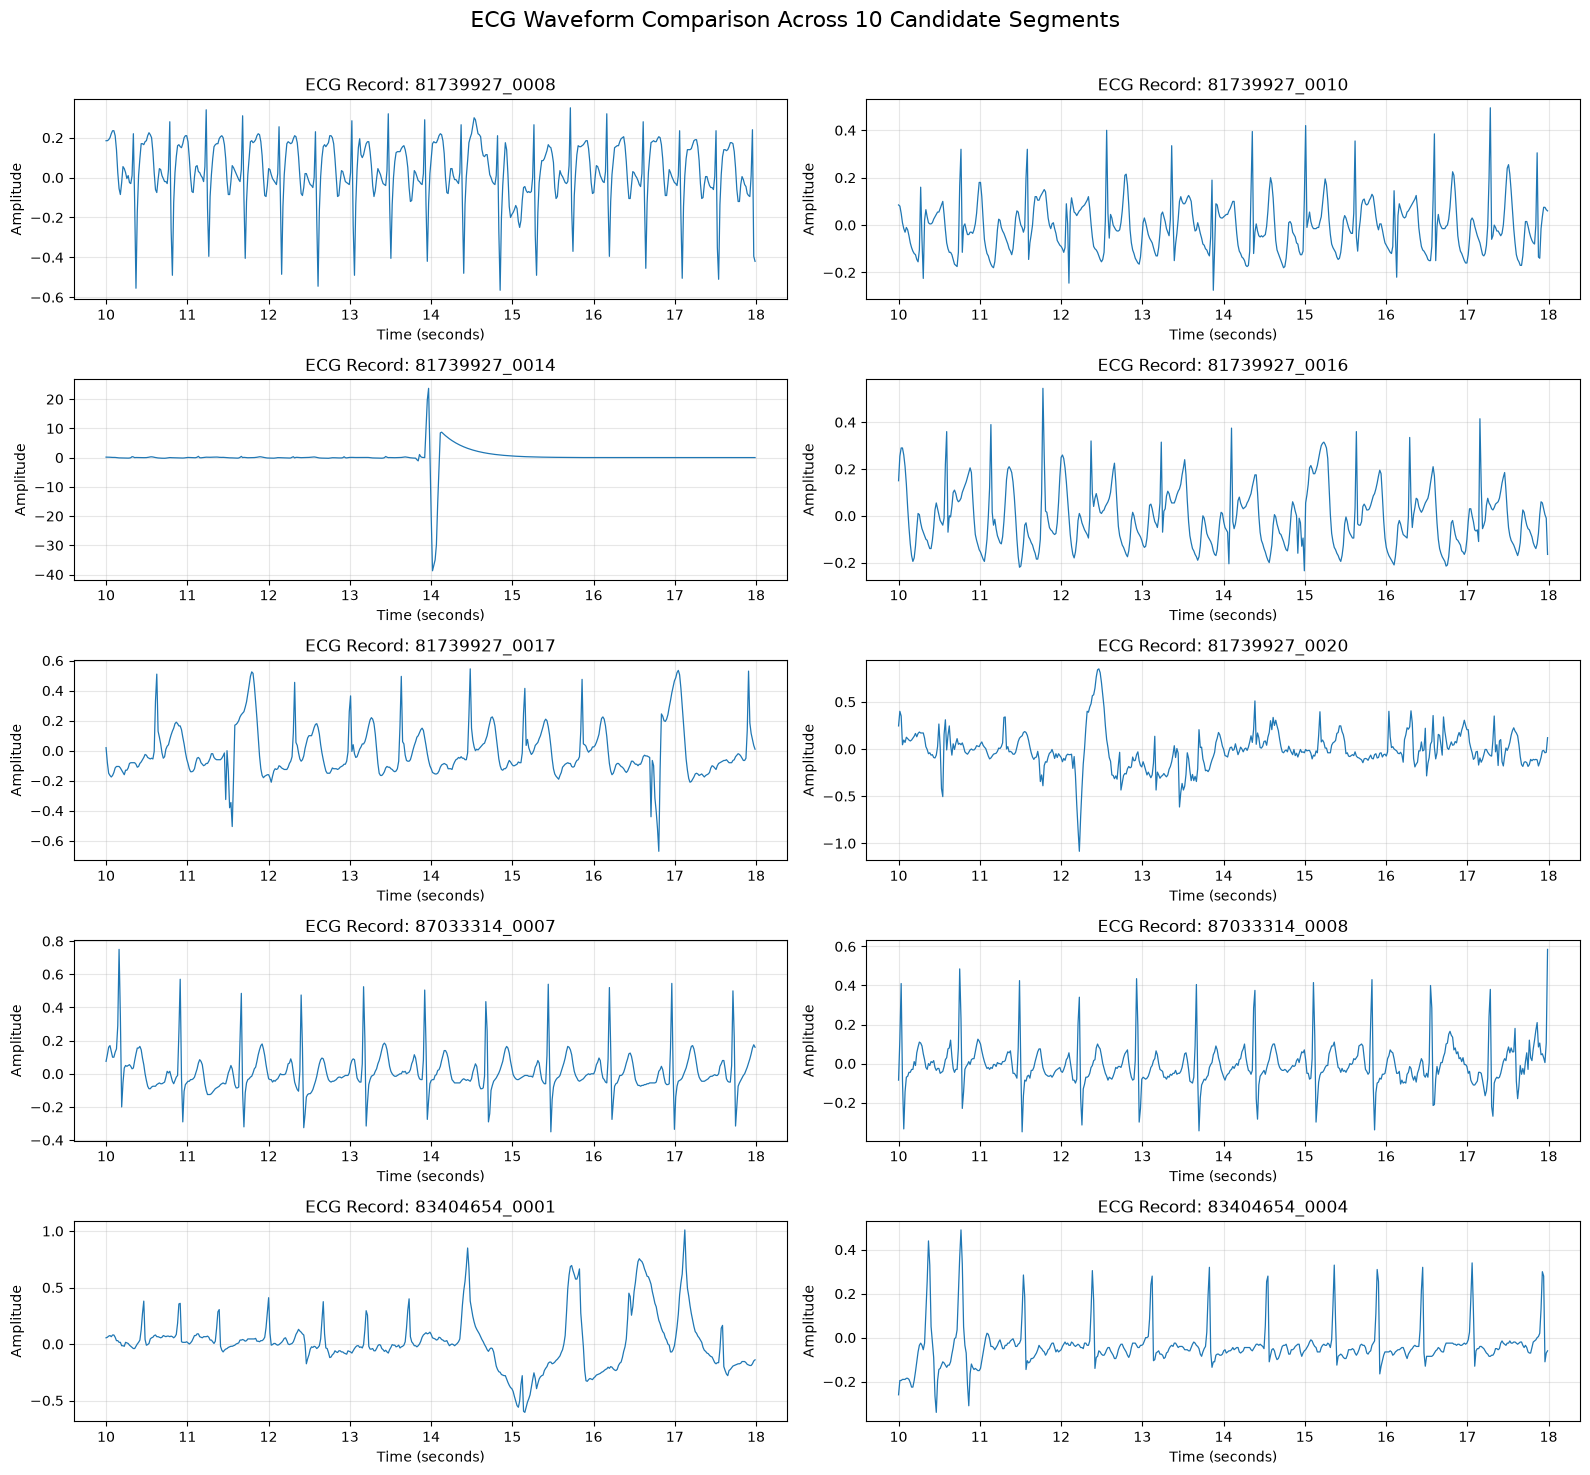

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# Create a 5 x 2 grid for 10 ECG records
fig, axes = plt.subplots(
    5, 2,
    figsize=(16, 15)
)

axes = axes.flatten()

for i, (record_id, signals) in enumerate(loaded_records.items()):

    ecg_signal = signals["ecg"]
    fs_record = signals["fs"]

    # Time axis in seconds
    time_axis = np.arange(len(ecg_signal)) / fs_record + 10

    axes[i].plot(time_axis, ecg_signal, linewidth=0.9)

    axes[i].set_title(f"ECG Record: {record_id}")
    axes[i].set_xlabel("Time (seconds)")
    axes[i].set_ylabel("Amplitude")
    axes[i].grid(True, alpha=0.3)

fig.suptitle(
    "ECG Waveform Comparison Across 10 Candidate Segments",
    fontsize=16
)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

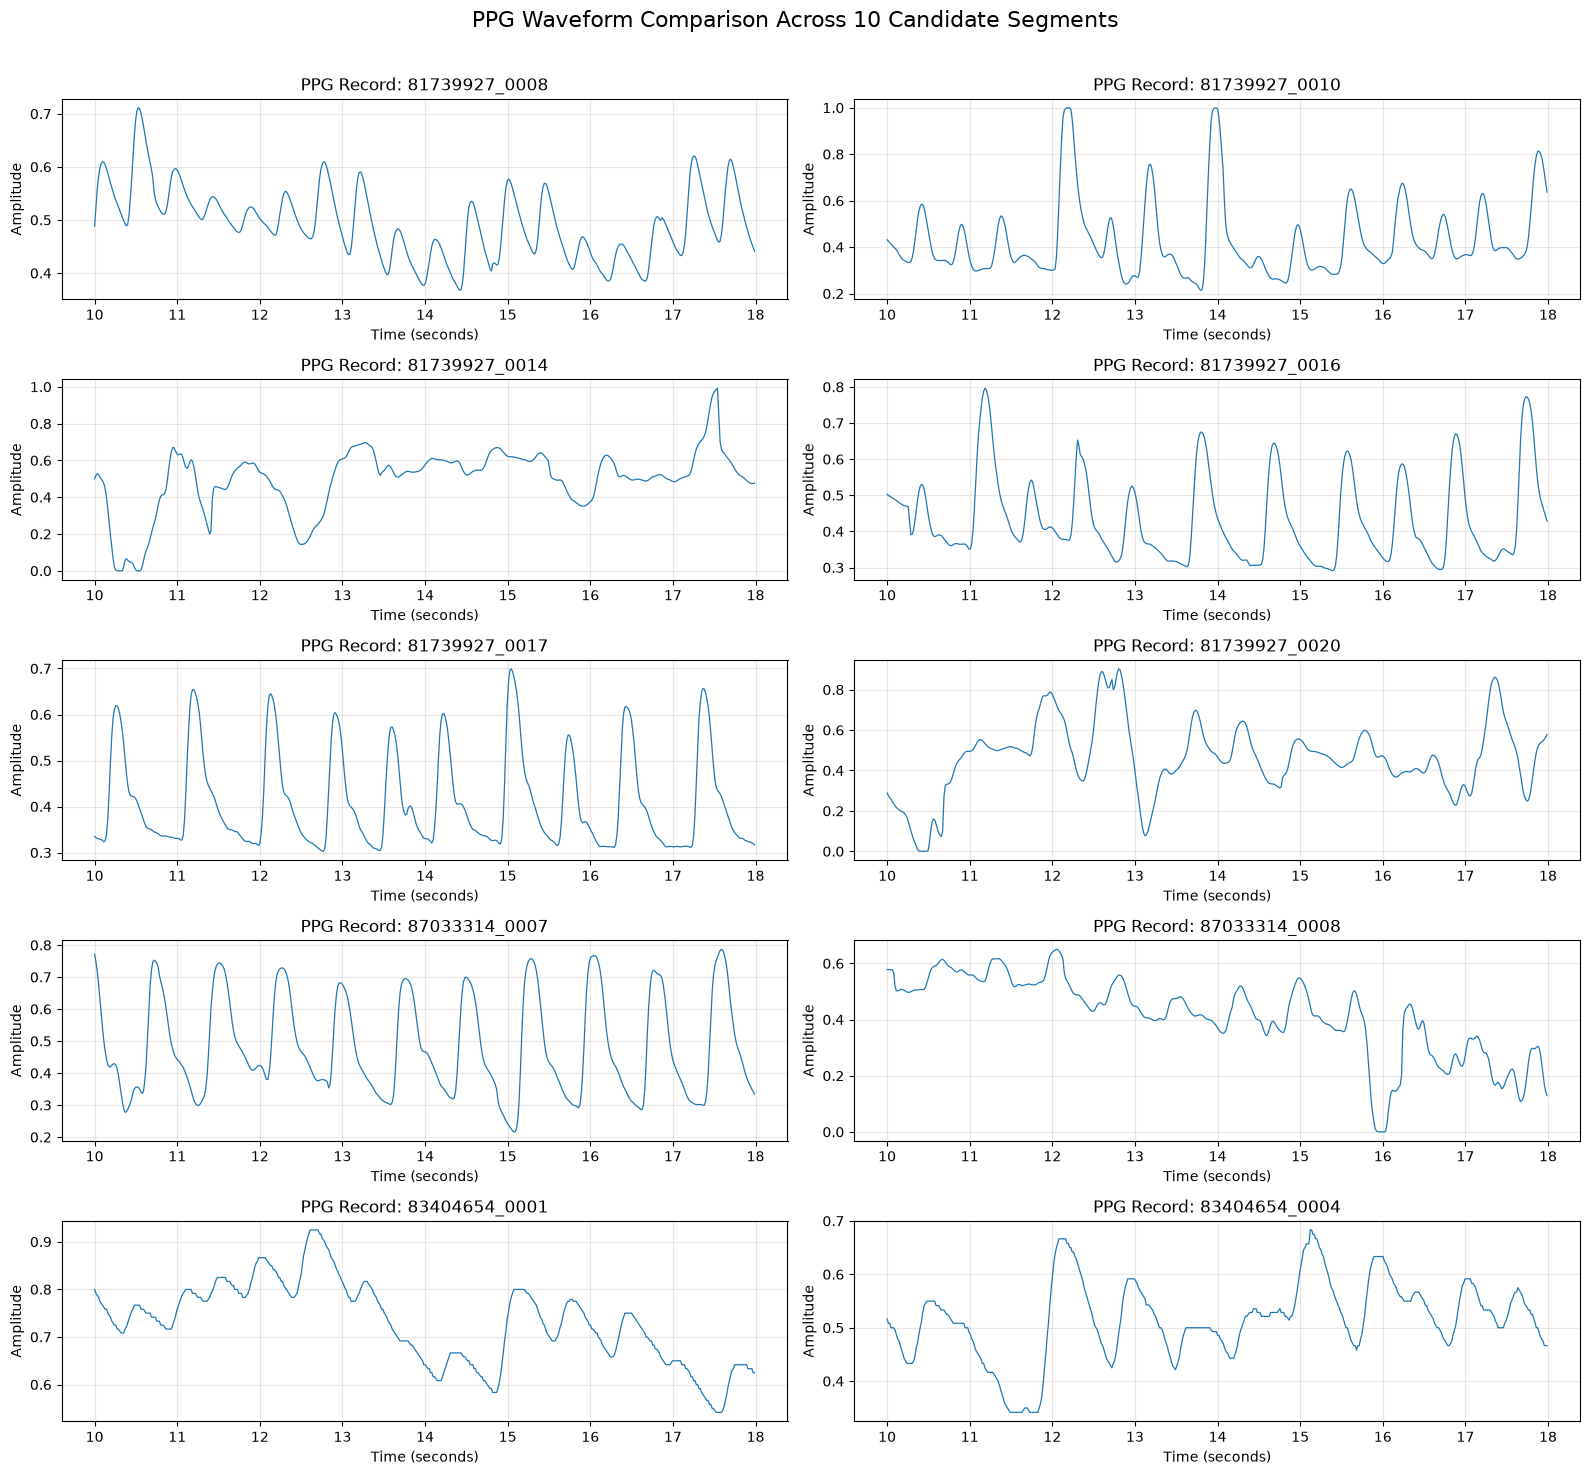

In [8]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(5, 2, figsize=(16, 15))
axes = axes.flatten()

for i, (record_id, signals) in enumerate(loaded_records.items()):

    ppg_signal = signals["ppg"]
    fs_record = signals["fs"]

    time_axis = np.arange(len(ppg_signal)) / fs_record + 10

    axes[i].plot(time_axis, ppg_signal, linewidth=0.9)

    axes[i].set_title(f"PPG Record: {record_id}")
    axes[i].set_xlabel("Time (seconds)")
    axes[i].set_ylabel("Amplitude")
    axes[i].grid(True, alpha=0.3)

fig.suptitle(
    "PPG Waveform Comparison Across 10 Candidate Segments",
    fontsize=16
)

plt.tight_layout(rect=[0, 0, 1, 0.97])

plt.savefig(
    "ppg_waveform_comparison_10_records.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

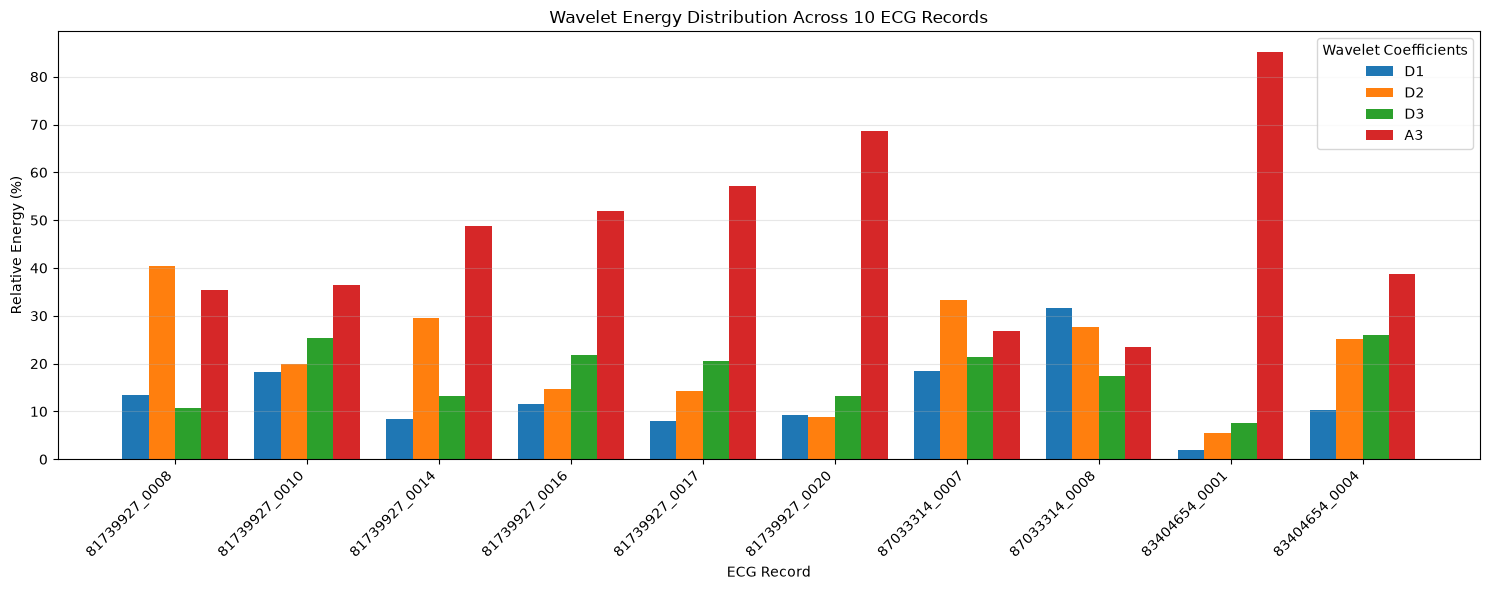

In [9]:
import matplotlib.pyplot as plt
import numpy as np

energy_columns = [
    "D1_Relative_Percent",
    "D2_Relative_Percent",
    "D3_Relative_Percent",
    "A3_Relative_Percent"
]

energy_labels = ["D1", "D2", "D3", "A3"]

x = np.arange(len(energy_df))
width = 0.2

fig, ax = plt.subplots(figsize=(15, 6))

for i, (column, label) in enumerate(
    zip(energy_columns, energy_labels)
):
    ax.bar(
        x + (i - 1.5) * width,
        energy_df[column],
        width,
        label=label
    )

ax.set_xlabel("ECG Record")
ax.set_ylabel("Relative Energy (%)")
ax.set_title("Wavelet Energy Distribution Across 10 ECG Records")

ax.set_xticks(x)
ax.set_xticklabels(
    energy_df["Record_ID"],
    rotation=45,
    ha="right"
)

ax.legend(title="Wavelet Coefficients")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "dwt_energy_comparison_10_records.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

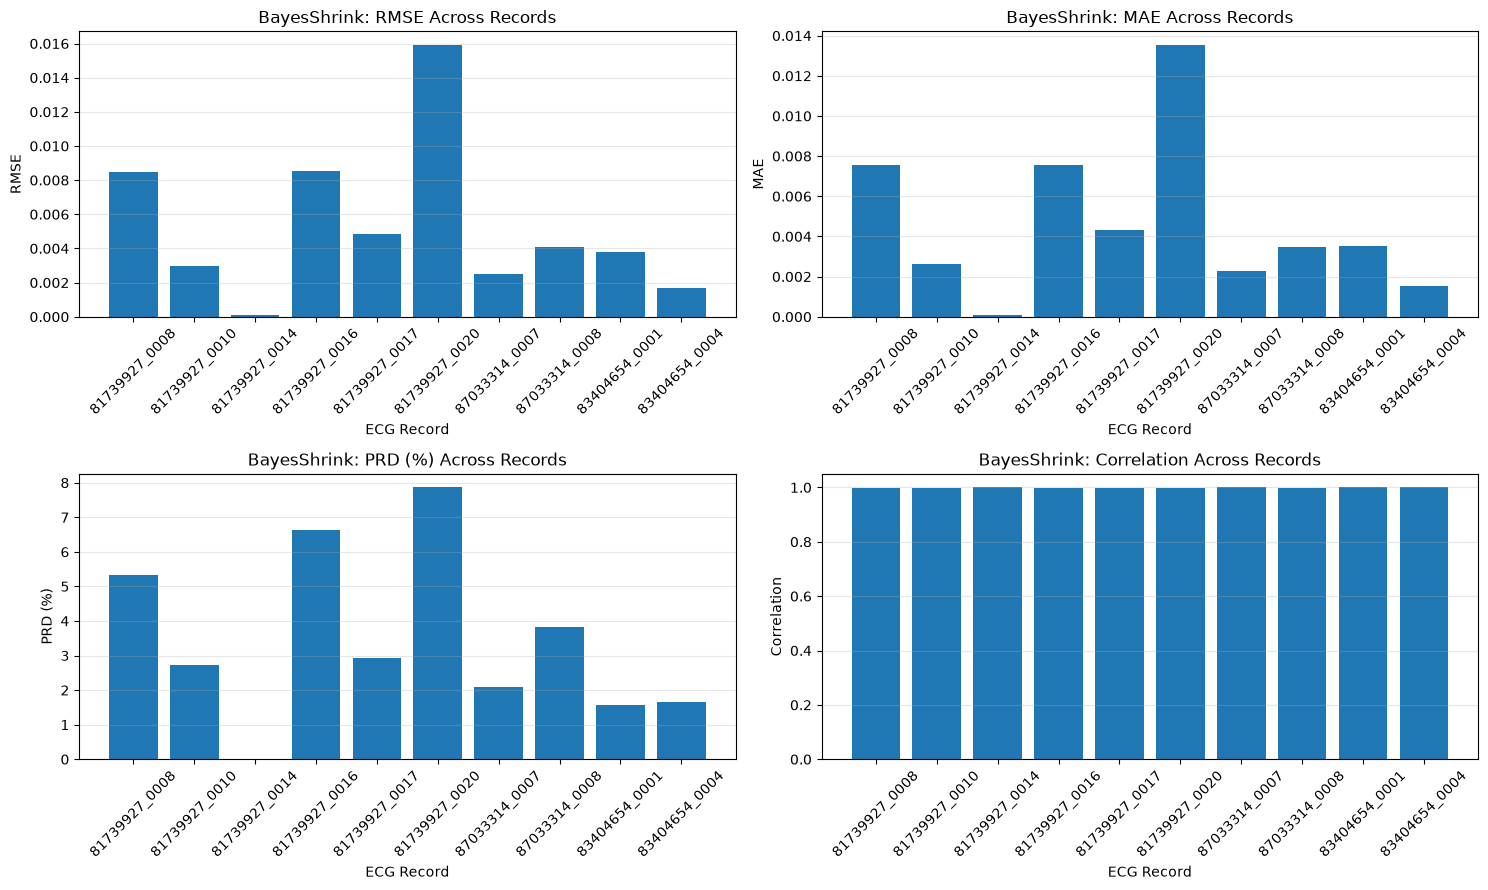

In [10]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 2, figsize=(15, 9))

metrics = [
    ("RMSE", "RMSE", axes[0, 0]),
    ("MAE", "MAE", axes[0, 1]),
    ("PRD_Percent", "PRD (%)", axes[1, 0]),
    ("Correlation", "Correlation", axes[1, 1])
]

for column, title, ax in metrics:
    ax.bar(
        bayes_df["Record_ID"],
        bayes_df[column]
    )
    ax.set_title(f"BayesShrink: {title} Across Records")
    ax.set_xlabel("ECG Record")
    ax.set_ylabel(title)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "bayesshrink_metrics_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

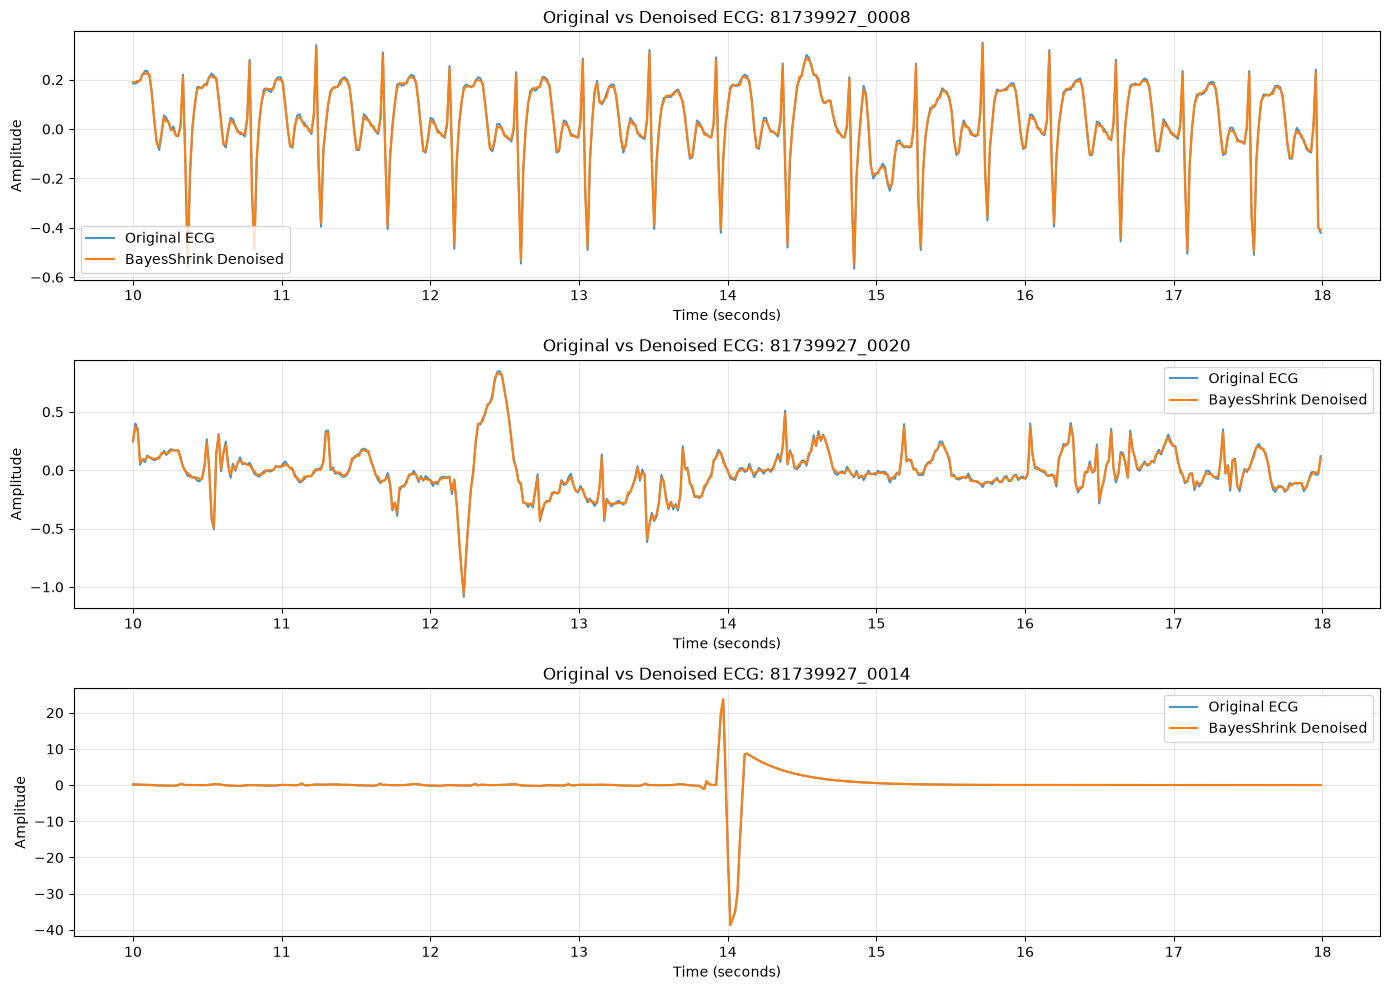

In [11]:
import matplotlib.pyplot as plt
import numpy as np
import pywt

selected_records = [
    "81739927_0008",
    "81739927_0020",
    "81739927_0014"
]

fig, axes = plt.subplots(3, 1, figsize=(14, 10))

for ax, record_id in zip(axes, selected_records):

    ecg_original = loaded_records[record_id]["ecg"]

    coeffs = pywt.wavedec(
        ecg_original,
        "haar",
        level=3
    )

    sigma = np.median(np.abs(coeffs[-1])) / 0.6745
    noise_var = sigma ** 2

    coeffs_bayes = [coeffs[0]]

    for detail in coeffs[1:]:

        signal_var = max(
            np.var(detail) - noise_var,
            0
        )

        if signal_var == 0:
            threshold = np.max(np.abs(detail))
        else:
            threshold = noise_var / np.sqrt(signal_var)

        coeffs_bayes.append(
            pywt.threshold(
                detail,
                threshold,
                mode="soft"
            )
        )

    ecg_denoised = pywt.waverec(
        coeffs_bayes,
        "haar"
    )[:len(ecg_original)]

    fs = loaded_records[record_id]["fs"]

    time_axis = np.arange(len(ecg_original)) / fs + 10

    ax.plot(
        time_axis,
        ecg_original,
        label="Original ECG",
        alpha=0.8
    )

    ax.plot(
        time_axis,
        ecg_denoised,
        label="BayesShrink Denoised",
        linewidth=1.5
    )

    ax.set_title(f"Original vs Denoised ECG: {record_id}")
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Amplitude")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    "original_vs_bayesshrink_selected_records.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [12]:
import numpy as np
import matplotlib.pyplot as plt

record_id = "81739927_0008"

ecg_clean_reference = loaded_records[record_id]["ecg"]
fs = loaded_records[record_id]["fs"]

# Reproducible random noise
np.random.seed(42)

# Target SNR for the controlled-noise experiment
target_snr_db = 10

signal_power = np.mean(ecg_clean_reference ** 2)

noise_power = signal_power / (10 ** (target_snr_db / 10))

noise = np.random.normal(
    0,
    np.sqrt(noise_power),
    size=len(ecg_clean_reference)
)

ecg_noisy = ecg_clean_reference + noise

# Verify the achieved SNR
actual_snr_db = 10 * np.log10(
    np.sum(ecg_clean_reference ** 2) /
    np.sum(noise ** 2)
)

print("Record:", record_id)
print("Sampling frequency:", fs, "Hz")
print("Number of samples:", len(ecg_clean_reference))
print("Target SNR:", target_snr_db, "dB")
print("Actual SNR:", round(actual_snr_db, 2), "dB")
print("Noise standard deviation:", round(np.std(noise), 5))

Record: 81739927_0008
Sampling frequency: 62.4725 Hz
Number of samples: 500
Target SNR: 10 dB
Actual SNR: 10.17 dB
Noise standard deviation: 0.0493


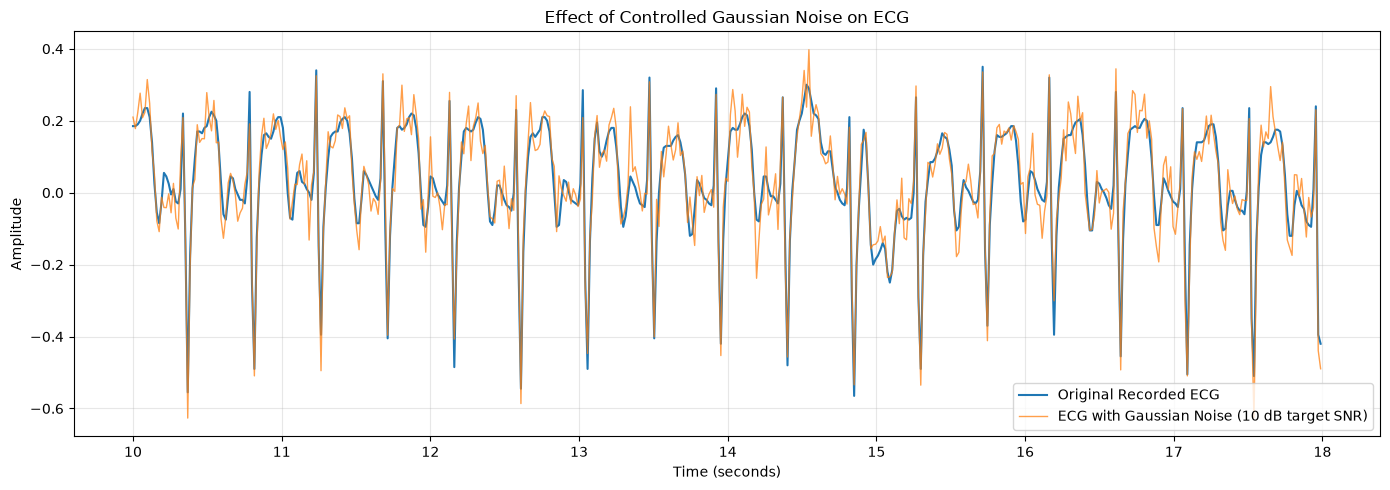

In [13]:
import matplotlib.pyplot as plt
import numpy as np

time_axis = np.arange(len(ecg_clean_reference)) / fs + 10

plt.figure(figsize=(14, 5))

plt.plot(
    time_axis,
    ecg_clean_reference,
    label="Original Recorded ECG",
    linewidth=1.5
)

plt.plot(
    time_axis,
    ecg_noisy,
    label="ECG with Gaussian Noise (10 dB target SNR)",
    alpha=0.75,
    linewidth=1
)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Effect of Controlled Gaussian Noise on ECG")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    "original_vs_noisy_ecg.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

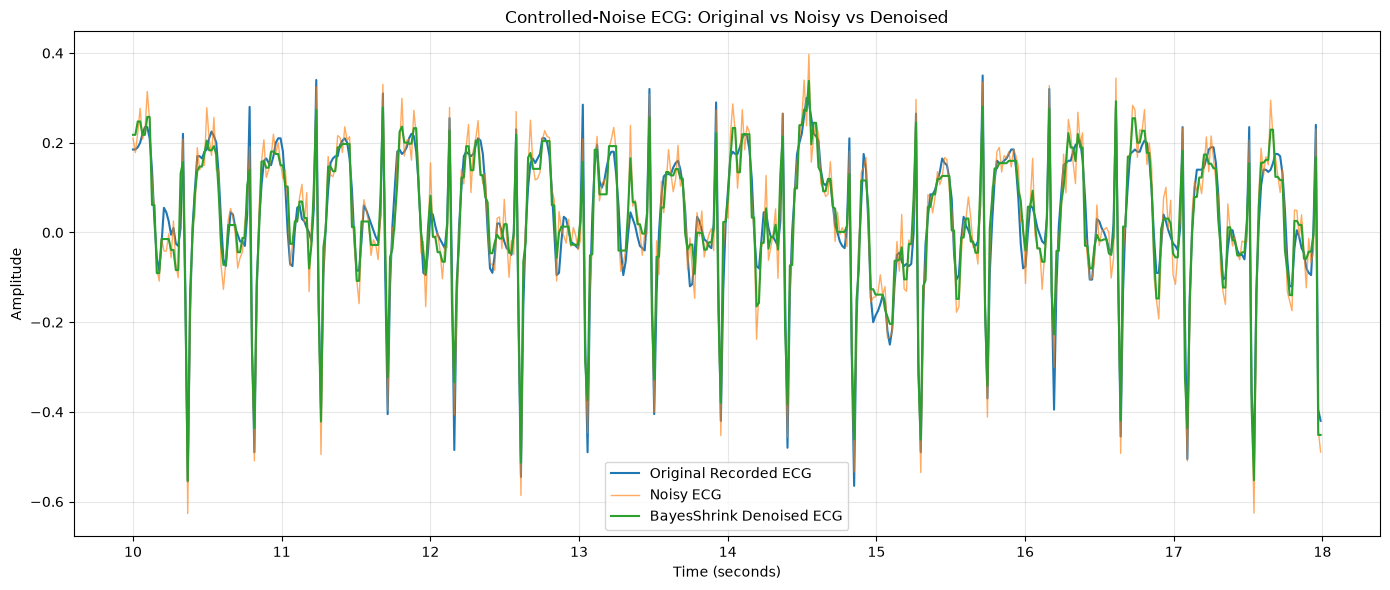

Estimated noise sigma: 0.06919
BayesShrink thresholds (D3, D2, D1):
[0.03069 0.02582 0.07001]


In [14]:
import numpy as np
import pywt
import matplotlib.pyplot as plt

# Step 1: Decompose the noisy ECG
coeffs_noisy = pywt.wavedec(
    ecg_noisy,
    "haar",
    level=3
)

# Step 2: Estimate noise variance from finest detail coefficients
sigma = np.median(
    np.abs(coeffs_noisy[-1])
) / 0.6745

noise_var = sigma ** 2

# Step 3: Apply BayesShrink thresholding
coeffs_denoised = [coeffs_noisy[0]]
thresholds = []

for detail in coeffs_noisy[1:]:

    signal_var = max(
        np.var(detail) - noise_var,
        0
    )

    if signal_var == 0:
        threshold = np.max(np.abs(detail))
    else:
        threshold = noise_var / np.sqrt(signal_var)

    thresholds.append(threshold)

    denoised_detail = pywt.threshold(
        detail,
        threshold,
        mode="soft"
    )

    coeffs_denoised.append(denoised_detail)

# Step 4: Reconstruct the denoised signal
ecg_denoised_controlled = pywt.waverec(
    coeffs_denoised,
    "haar"
)

ecg_denoised_controlled = (
    ecg_denoised_controlled[:len(ecg_noisy)]
)

# Step 5: Plot all three signals
time_axis = np.arange(len(ecg_clean_reference)) / fs + 10

plt.figure(figsize=(14, 6))

plt.plot(
    time_axis,
    ecg_clean_reference,
    label="Original Recorded ECG",
    linewidth=1.5
)

plt.plot(
    time_axis,
    ecg_noisy,
    label="Noisy ECG",
    alpha=0.65,
    linewidth=1
)

plt.plot(
    time_axis,
    ecg_denoised_controlled,
    label="BayesShrink Denoised ECG",
    linewidth=1.5
)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Controlled-Noise ECG: Original vs Noisy vs Denoised")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    "controlled_noise_bayesshrink_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Estimated noise sigma:", round(sigma, 5))
print("BayesShrink thresholds (D3, D2, D1):")
print(np.round(thresholds, 5))

In [15]:
import numpy as np
import pandas as pd

reference = ecg_clean_reference
noisy = ecg_noisy
denoised = ecg_denoised_controlled

# Ensure all signals have the same length
n = min(len(reference), len(noisy), len(denoised))

reference = reference[:n]
noisy = noisy[:n]
denoised = denoised[:n]

# Errors relative to the original recorded ECG
noisy_error = noisy - reference
denoised_error = denoised - reference

# RMSE
rmse_noisy = np.sqrt(np.mean(noisy_error ** 2))
rmse_denoised = np.sqrt(np.mean(denoised_error ** 2))

# MAE
mae_noisy = np.mean(np.abs(noisy_error))
mae_denoised = np.mean(np.abs(denoised_error))

# Normalized RMSE
signal_range = np.max(reference) - np.min(reference)

nrmse_noisy = rmse_noisy / signal_range
nrmse_denoised = rmse_denoised / signal_range

# PRD
reference_energy = np.sum(reference ** 2)

prd_noisy = 100 * np.sqrt(
    np.sum(noisy_error ** 2) / reference_energy
)

prd_denoised = 100 * np.sqrt(
    np.sum(denoised_error ** 2) / reference_energy
)

# SNR relative to the recorded reference
snr_noisy = 10 * np.log10(
    np.sum(reference ** 2) /
    np.sum(noisy_error ** 2)
)

snr_denoised = 10 * np.log10(
    np.sum(reference ** 2) /
    np.sum(denoised_error ** 2)
)

# Correlation with the reference
corr_noisy = np.corrcoef(reference, noisy)[0, 1]
corr_denoised = np.corrcoef(reference, denoised)[0, 1]

results_df = pd.DataFrame({
    "Metric": [
        "RMSE",
        "MAE",
        "NRMSE",
        "PRD (%)",
        "SNR (dB)",
        "Correlation"
    ],
    "Noisy ECG": [
        rmse_noisy,
        mae_noisy,
        nrmse_noisy,
        prd_noisy,
        snr_noisy,
        corr_noisy
    ],
    "BayesShrink Denoised": [
        rmse_denoised,
        mae_denoised,
        nrmse_denoised,
        prd_denoised,
        snr_denoised,
        corr_denoised
    ]
})

display(results_df.round(5))

print(
    "SNR improvement:",
    round(snr_denoised - snr_noisy, 3),
    "dB"
)

,Metric,Noisy ECG,BayesShrink Denoised
0,RMSE,0.04930,0.04477
1,MAE,0.03919,0.03496
2,NRMSE,0.05388,0.04893
3,PRD (%),30.99966,28.15022
4,SNR (dB),10.17286,11.01036
5,Correlation,0.95536,0.95785


SNR improvement: 0.838 dB


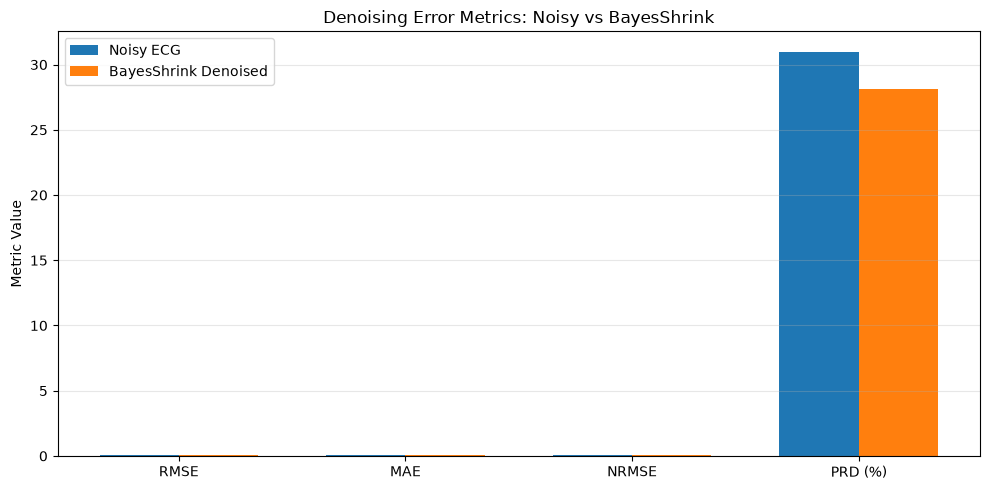

In [16]:
import matplotlib.pyplot as plt
import numpy as np

metric_names = ["RMSE", "MAE", "NRMSE", "PRD (%)"]

noisy_values = [
    rmse_noisy,
    mae_noisy,
    nrmse_noisy,
    prd_noisy
]

denoised_values = [
    rmse_denoised,
    mae_denoised,
    nrmse_denoised,
    prd_denoised
]

x = np.arange(len(metric_names))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    x - width / 2,
    noisy_values,
    width,
    label="Noisy ECG"
)

ax.bar(
    x + width / 2,
    denoised_values,
    width,
    label="BayesShrink Denoised"
)

ax.set_xticks(x)
ax.set_xticklabels(metric_names)
ax.set_ylabel("Metric Value")
ax.set_title("Denoising Error Metrics: Noisy vs BayesShrink")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "controlled_noise_metrics_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

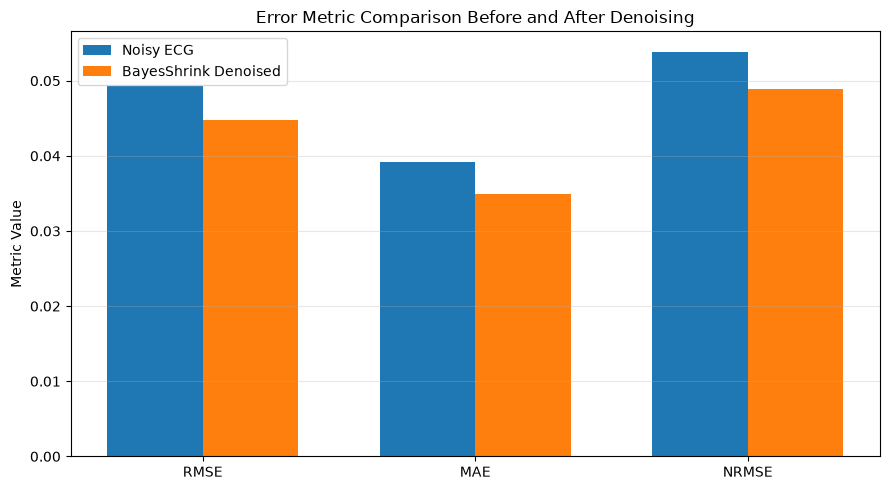

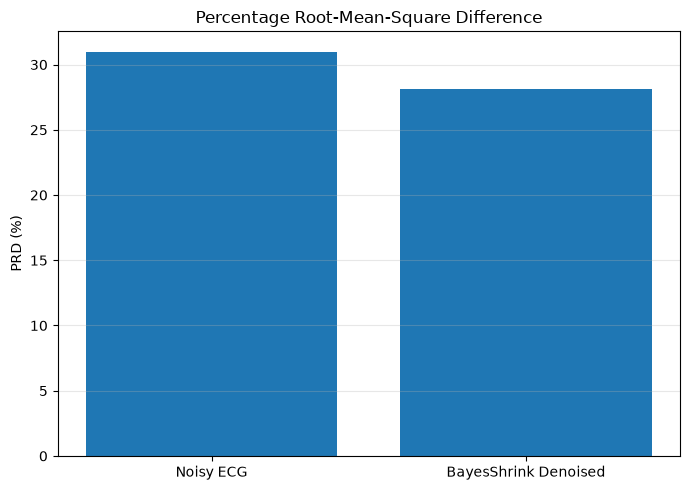

In [17]:
import matplotlib.pyplot as plt
import numpy as np

# Plot 1: RMSE, MAE, NRMSE
metrics_small = ["RMSE", "MAE", "NRMSE"]

noisy_small = [
    rmse_noisy,
    mae_noisy,
    nrmse_noisy
]

denoised_small = [
    rmse_denoised,
    mae_denoised,
    nrmse_denoised
]

x = np.arange(len(metrics_small))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    x - width / 2,
    noisy_small,
    width,
    label="Noisy ECG"
)

ax.bar(
    x + width / 2,
    denoised_small,
    width,
    label="BayesShrink Denoised"
)

ax.set_xticks(x)
ax.set_xticklabels(metrics_small)
ax.set_ylabel("Metric Value")
ax.set_title("Error Metric Comparison Before and After Denoising")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "error_metrics_comparison_clear.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Plot 2: PRD
fig, ax = plt.subplots(figsize=(7, 5))

ax.bar(
    ["Noisy ECG", "BayesShrink Denoised"],
    [prd_noisy, prd_denoised]
)

ax.set_ylabel("PRD (%)")
ax.set_title("Percentage Root-Mean-Square Difference")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "prd_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [18]:
import numpy as np
import pywt
import pandas as pd

record_id = "81739927_0008"

reference = loaded_records[record_id]["ecg"]
np.random.seed(42)

target_snr_levels = [5, 10, 15]
multi_snr_results = []

for target_snr in target_snr_levels:

    # Add Gaussian noise at the target SNR
    signal_power = np.mean(reference ** 2)
    noise_power = signal_power / (10 ** (target_snr / 10))

    noise = np.random.normal(
        0,
        np.sqrt(noise_power),
        size=len(reference)
    )

    noisy_signal = reference + noise

    actual_snr = 10 * np.log10(
        np.sum(reference ** 2) / np.sum(noise ** 2)
    )

    # Three-level Haar wavelet decomposition
    coeffs = pywt.wavedec(
        noisy_signal,
        "haar",
        level=3
    )

    # Estimate noise and apply BayesShrink
    sigma = np.median(np.abs(coeffs[-1])) / 0.6745
    noise_var = sigma ** 2

    denoised_coeffs = [coeffs[0]]

    for detail in coeffs[1:]:

        signal_var = max(
            np.var(detail) - noise_var,
            0
        )

        if signal_var == 0:
            threshold = np.max(np.abs(detail))
        else:
            threshold = noise_var / np.sqrt(signal_var)

        denoised_coeffs.append(
            pywt.threshold(
                detail,
                threshold,
                mode="soft"
            )
        )

    denoised_signal = pywt.waverec(
        denoised_coeffs,
        "haar"
    )[:len(reference)]

    # Calculate error relative to the recorded reference
    noisy_error = noisy_signal - reference
    denoised_error = denoised_signal - reference

    noisy_snr = 10 * np.log10(
        np.sum(reference ** 2) / np.sum(noisy_error ** 2)
    )

    denoised_snr = 10 * np.log10(
        np.sum(reference ** 2) / np.sum(denoised_error ** 2)
    )

    multi_snr_results.append({
        "Target_SNR_dB": target_snr,
        "Actual_SNR_dB": actual_snr,
        "Noisy_RMSE": np.sqrt(np.mean(noisy_error ** 2)),
        "Denoised_RMSE": np.sqrt(np.mean(denoised_error ** 2)),
        "Noisy_SNR_dB": noisy_snr,
        "Denoised_SNR_dB": denoised_snr,
        "SNR_Improvement_dB": denoised_snr - noisy_snr
    })

multi_snr_df = pd.DataFrame(multi_snr_results)

display(multi_snr_df.round(4))

,Target_SNR_dB,Actual_SNR_dB,Noisy_RMSE,Denoised_RMSE,Noisy_SNR_dB,Denoised_SNR_dB,SNR_Improvement_dB
0,5,5.1729,0.0877,0.0718,5.1729,6.9073,1.7344
1,10,10.1973,0.0492,0.0503,10.1973,9.9962,-0.2011
2,15,14.8703,0.0287,0.0299,14.8703,14.5151,-0.3552


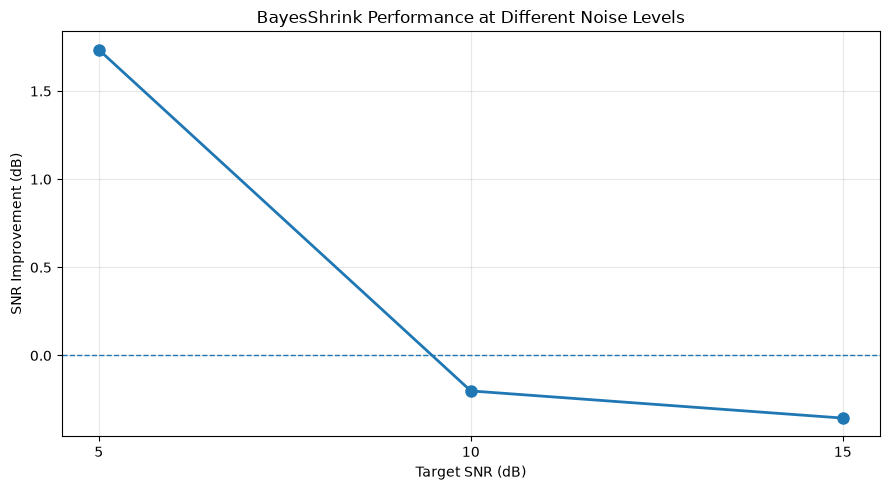

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    multi_snr_df["Target_SNR_dB"],
    multi_snr_df["SNR_Improvement_dB"],
    marker="o",
    linewidth=2,
    markersize=8
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

plt.xlabel("Target SNR (dB)")
plt.ylabel("SNR Improvement (dB)")
plt.title("BayesShrink Performance at Different Noise Levels")

plt.xticks([5, 10, 15])
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    "snr_improvement_across_noise_levels.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [20]:
import numpy as np
import pywt
import pandas as pd

reference = loaded_records["81739927_0008"]["ecg"]

snr_levels = [5, 10, 15]
n_trials = 20

rng = np.random.default_rng(42)
trial_results = []

for target_snr in snr_levels:

    for trial in range(n_trials):

        # Generate noise for this trial
        signal_power = np.mean(reference ** 2)
        noise_power = signal_power / (10 ** (target_snr / 10))

        noise = rng.normal(
            0,
            np.sqrt(noise_power),
            size=len(reference)
        )

        noisy_signal = reference + noise

        # DWT decomposition
        coeffs = pywt.wavedec(
            noisy_signal,
            "haar",
            level=3
        )

        # Estimate noise variance
        sigma = np.median(np.abs(coeffs[-1])) / 0.6745
        noise_var = sigma ** 2

        # BayesShrink soft thresholding
        denoised_coeffs = [coeffs[0]]

        for detail in coeffs[1:]:

            signal_var = max(
                np.var(detail) - noise_var,
                0
            )

            if signal_var == 0:
                threshold = np.max(np.abs(detail))
            else:
                threshold = noise_var / np.sqrt(signal_var)

            denoised_coeffs.append(
                pywt.threshold(
                    detail,
                    threshold,
                    mode="soft"
                )
            )

        denoised_signal = pywt.waverec(
            denoised_coeffs,
            "haar"
        )[:len(reference)]

        # Calculate reference-relative SNRs
        noisy_error = noisy_signal - reference
        denoised_error = denoised_signal - reference

        noisy_snr = 10 * np.log10(
            np.sum(reference ** 2) /
            np.sum(noisy_error ** 2)
        )

        denoised_snr = 10 * np.log10(
            np.sum(reference ** 2) /
            np.sum(denoised_error ** 2)
        )

        trial_results.append({
            "Target_SNR_dB": target_snr,
            "Trial": trial + 1,
            "SNR_Improvement_dB": denoised_snr - noisy_snr
        })

trials_df = pd.DataFrame(trial_results)

summary_df = (
    trials_df.groupby("Target_SNR_dB")["SNR_Improvement_dB"]
    .agg(["mean", "std", "min", "max"])
    .reset_index()
)

summary_df.columns = [
    "Target_SNR_dB",
    "Mean_Improvement_dB",
    "Std_Improvement_dB",
    "Minimum_dB",
    "Maximum_dB"
]

display(summary_df.round(4))

,Target_SNR_dB,Mean_Improvement_dB,Std_Improvement_dB,Minimum_dB,Maximum_dB
0,5,0.9680,0.6204,-0.1676,1.9507
1,10,-0.1727,0.6566,-1.8440,0.8355
2,15,-0.6655,0.6666,-2.0212,0.5303


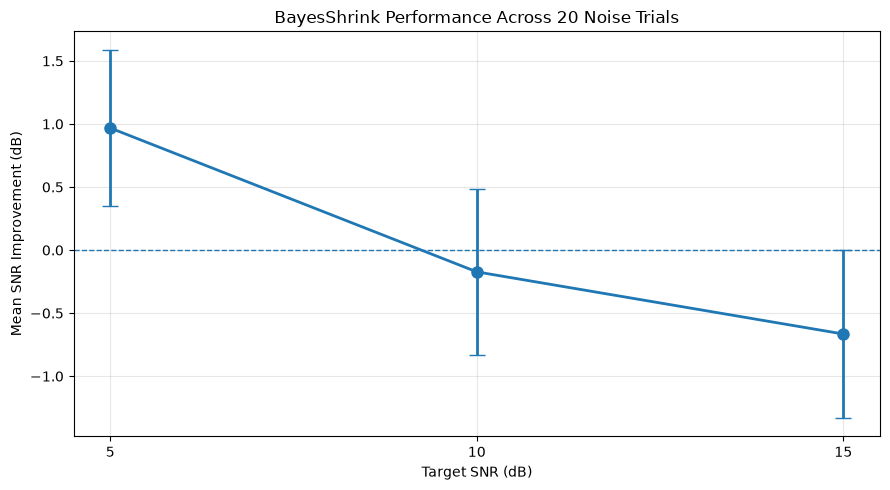

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.errorbar(
    summary_df["Target_SNR_dB"],
    summary_df["Mean_Improvement_dB"],
    yerr=summary_df["Std_Improvement_dB"],
    fmt="o-",
    capsize=6,
    linewidth=2,
    markersize=8
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

plt.xticks([5, 10, 15])
plt.xlabel("Target SNR (dB)")
plt.ylabel("Mean SNR Improvement (dB)")
plt.title("BayesShrink Performance Across 20 Noise Trials")
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    "bayesshrink_mean_snr_improvement_errorbars.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [22]:
# Check all 10 selected ECG records

print("Total records:", len(loaded_records))
print("-" * 50)

for record_id, signals in loaded_records.items():
    ecg_signal = signals["ecg"]
    ppg_signal = signals["ppg"]
    fs = signals["fs"]

    print(
        f"{record_id} | "
        f"ECG samples: {len(ecg_signal)} | "
        f"PPG samples: {len(ppg_signal)} | "
        f"Sampling frequency: {fs:.4f} Hz"
    )

Total records: 10
--------------------------------------------------
81739927_0008 | ECG samples: 500 | PPG samples: 500 | Sampling frequency: 62.4725 Hz
81739927_0010 | ECG samples: 500 | PPG samples: 500 | Sampling frequency: 62.4725 Hz
81739927_0014 | ECG samples: 500 | PPG samples: 500 | Sampling frequency: 62.4725 Hz
81739927_0016 | ECG samples: 500 | PPG samples: 500 | Sampling frequency: 62.4725 Hz
81739927_0017 | ECG samples: 500 | PPG samples: 500 | Sampling frequency: 62.4725 Hz
81739927_0020 | ECG samples: 500 | PPG samples: 500 | Sampling frequency: 62.4725 Hz
87033314_0007 | ECG samples: 500 | PPG samples: 500 | Sampling frequency: 62.4725 Hz
87033314_0008 | ECG samples: 500 | PPG samples: 500 | Sampling frequency: 62.4725 Hz
83404654_0001 | ECG samples: 500 | PPG samples: 500 | Sampling frequency: 62.4725 Hz
83404654_0004 | ECG samples: 500 | PPG samples: 500 | Sampling frequency: 62.4725 Hz


In [80]:
import numpy as np
import pandas as pd
import pywt

# Four wavelet families for comparison
wavelets = ["haar", "db4", "sym4", "coif1"]

print("PyWavelets version:", pywt.__version__)
print("\nWavelets available:")

for name in wavelets:
    wavelet = pywt.Wavelet(name)
    print(f"{name}: {wavelet.name}")

PyWavelets version: 1.8.0

Wavelets available:
haar: haar
db4: db4
sym4: sym4
coif1: coif1


In [81]:
import numpy as np
import pandas as pd

# Reproducible experiment
rng = np.random.default_rng(42)

target_snr_db = 10
noisy_records = {}

for record_id, signals in loaded_records.items():

    # Original ECG signal
    original_ecg = np.asarray(signals["ecg"], dtype=float)

    # Calculate signal power
    signal_power = np.mean(original_ecg ** 2)

    # Calculate noise power for target SNR
    noise_power = signal_power / (10 ** (target_snr_db / 10))

    # Generate Gaussian noise
    noise = rng.normal(
        loc=0,
        scale=np.sqrt(noise_power),
        size=len(original_ecg)
    )

    # Add noise to the original ECG
    noisy_ecg = original_ecg + noise

    # Measure actual SNR
    actual_snr = 10 * np.log10(
        signal_power / np.mean(noise ** 2)
    )

    noisy_records[record_id] = {
        "original": original_ecg.copy(),
        "noisy": noisy_ecg,
        "noise": noise,
        "fs": signals["fs"],
        "actual_snr_db": actual_snr
    }

# Display results
noise_summary = pd.DataFrame([
    {
        "Record_ID": record_id,
        "Samples": len(data["original"]),
        "Target_SNR_dB": target_snr_db,
        "Actual_SNR_dB": round(data["actual_snr_db"], 2),
        "Noise_STD": round(np.std(data["noise"]), 5)
    }
    for record_id, data in noisy_records.items()
])

display(noise_summary)

,Record_ID,Samples,Target_SNR_dB,Actual_SNR_dB,Noise_STD
0,81739927_0008,500,10,10.36,0.04823
1,81739927_0010,500,10,9.84,0.03506
2,81739927_0014,500,10,9.83,1.25407
3,81739927_0016,500,10,9.88,0.04083
4,81739927_0017,500,10,9.84,0.05296
5,81739927_0020,500,10,9.88,0.06479
6,87033314_0007,500,10,10.30,0.03679
7,87033314_0008,500,10,10.12,0.03343
8,83404654_0001,500,10,10.14,0.07514
9,83404654_0004,500,10,9.90,0.03234


In [82]:
import numpy as np
import pywt
import pandas as pd

wavelets = ["haar", "db4", "sym4", "coif1"]

wavelet_results = {}

def bayes_shrink_denoise(signal, wavelet_name, level=3):

    signal = np.asarray(signal, dtype=float)

    # Discrete Wavelet Transform
    coeffs = pywt.wavedec(
        signal,
        wavelet=wavelet_name,
        level=level,
        mode="symmetric"
    )

    # Estimate noise from finest detail coefficients
    detail_1 = coeffs[-1]

    sigma = np.median(
        np.abs(detail_1 - np.median(detail_1))
    ) / 0.6745

    # Keep approximation coefficients unchanged
    denoised_coeffs = [coeffs[0]]

    # Apply BayesShrink soft thresholding
    for detail in coeffs[1:]:

        variance = np.var(detail)
        noise_variance = sigma ** 2

        signal_variance = max(
            variance - noise_variance,
            0.0
        )

        if signal_variance <= 1e-12:
            threshold = np.max(np.abs(detail))
        else:
            threshold = noise_variance / np.sqrt(signal_variance)

        denoised_detail = pywt.threshold(
            detail,
            value=threshold,
            mode="soft"
        )

        denoised_coeffs.append(denoised_detail)

    # Reconstruct the denoised signal
    reconstructed = pywt.waverec(
        denoised_coeffs,
        wavelet=wavelet_name,
        mode="symmetric"
    )

    # Match reconstructed length to original length
    reconstructed = reconstructed[:len(signal)]

    return reconstructed, sigma


# Denoise all 10 noisy ECG signals with all 4 wavelets
for record_id, data in noisy_records.items():

    original = data["original"]
    noisy = data["noisy"]

    wavelet_results[record_id] = {}

    for wavelet_name in wavelets:

        denoised, estimated_sigma = bayes_shrink_denoise(
            noisy,
            wavelet_name,
            level=3
        )

        wavelet_results[record_id][wavelet_name] = {
            "denoised": denoised,
            "estimated_sigma": estimated_sigma
        }

print("Denoising completed!")
print("Records processed:", len(wavelet_results))
print("Wavelets per record:", len(wavelets))

for record_id in wavelet_results:
    print(record_id, ":", list(wavelet_results[record_id].keys()))

Denoising completed!
Records processed: 10
Wavelets per record: 4
81739927_0008 : ['haar', 'db4', 'sym4', 'coif1']
81739927_0010 : ['haar', 'db4', 'sym4', 'coif1']
81739927_0014 : ['haar', 'db4', 'sym4', 'coif1']
81739927_0016 : ['haar', 'db4', 'sym4', 'coif1']
81739927_0017 : ['haar', 'db4', 'sym4', 'coif1']
81739927_0020 : ['haar', 'db4', 'sym4', 'coif1']
87033314_0007 : ['haar', 'db4', 'sym4', 'coif1']
87033314_0008 : ['haar', 'db4', 'sym4', 'coif1']
83404654_0001 : ['haar', 'db4', 'sym4', 'coif1']
83404654_0004 : ['haar', 'db4', 'sym4', 'coif1']


In [83]:
import numpy as np
import pandas as pd

comparison_results = []

for record_id, data in noisy_records.items():

    original = data["original"]
    noisy = data["noisy"]

    # Power of the original reference signal
    signal_power = np.mean(original ** 2)

    # Error before denoising
    noisy_error = noisy - original
    noisy_rmse = np.sqrt(np.mean(noisy_error ** 2))

    noisy_snr = 10 * np.log10(
        signal_power / np.mean(noisy_error ** 2)
    )

    for wavelet_name in wavelets:

        denoised = wavelet_results[record_id][wavelet_name]["denoised"]

        # Error after denoising
        error = denoised - original

        rmse = np.sqrt(np.mean(error ** 2))
        mae = np.mean(np.abs(error))

        signal_range = np.max(original) - np.min(original)

        nrmse = rmse / signal_range if signal_range != 0 else np.nan

        original_energy = np.sum(original ** 2)

        prd = (
            100 * np.sqrt(np.sum(error ** 2) / original_energy)
            if original_energy > 0 else np.nan
        )

        correlation = (
            np.corrcoef(original, denoised)[0, 1]
            if np.std(original) > 0 and np.std(denoised) > 0
            else np.nan
        )

        denoised_snr = (
            10 * np.log10(signal_power / np.mean(error ** 2))
            if np.mean(error ** 2) > 0 else np.inf
        )

        comparison_results.append({
            "Record_ID": record_id,
            "Wavelet": wavelet_name,
            "RMSE": rmse,
            "MAE": mae,
            "NRMSE": nrmse,
            "PRD_Percent": prd,
            "Correlation": correlation,
            "SNR_Before_dB": noisy_snr,
            "SNR_After_dB": denoised_snr,
            "SNR_Improvement_dB": denoised_snr - noisy_snr
        })

comparison_df = pd.DataFrame(comparison_results)

print("Total comparison rows:", len(comparison_df))
display(comparison_df.round(4))

Total comparison rows: 40


,Record_ID,Wavelet,RMSE,MAE,NRMSE,PRD_Percent,Correlation,SNR_Before_dB,SNR_After_dB,SNR_Improvement_dB
0,81739927_0008,haar,0.0446,0.0350,0.0487,28.0156,0.9583,10.3631,11.0520,0.6889
1,81739927_0008,db4,0.0418,0.0331,0.0457,26.2746,0.9634,10.3631,11.6093,1.2462
2,81739927_0008,sym4,0.0423,0.0333,0.0462,26.5683,0.9627,10.3631,11.5127,1.1497
3,81739927_0008,coif1,0.0424,0.0334,0.0463,26.6473,0.9623,10.3631,11.4869,1.1239
4,81739927_0010,haar,0.0306,0.0236,0.0398,28.1207,0.9596,9.8422,11.0195,1.1773
5,81739927_0010,db4,0.0299,0.0223,0.0388,27.4301,0.9616,9.8422,11.2354,1.3933
6,81739927_0010,sym4,0.0293,0.0222,0.0381,26.8917,0.9633,9.8422,11.4076,1.5655
7,81739927_0010,coif1,0.0294,0.0221,0.0382,27.0047,0.9628,9.8422,11.3712,1.5291
8,81739927_0014,haar,0.8770,0.6660,0.0140,22.5636,0.9746,9.8255,12.9318,3.1063
9,81739927_0014,db4,0.9014,0.6687,0.0144,23.1902,0.9730,9.8255,12.6939,2.8684


In [84]:
# Step 6: Overall wavelet performance comparison

import pandas as pd
import matplotlib.pyplot as plt

# All 10 records
summary_all = (
    comparison_df
    .groupby("Wavelet")[
        ["RMSE", "MAE", "NRMSE", "PRD_Percent",
         "Correlation", "SNR_Improvement_dB"]
    ]
    .mean()
    .round(4)
)

print("=== Average performance: All 10 records ===")
display(summary_all)

# Sensitivity analysis: exclude the flagged spike record
flagged_record = "81739927_0014"

comparison_without_spike = comparison_df[
    comparison_df["Record_ID"] != flagged_record
]

summary_without_spike = (
    comparison_without_spike
    .groupby("Wavelet")[
        ["RMSE", "MAE", "NRMSE", "PRD_Percent",
         "Correlation", "SNR_Improvement_dB"]
    ]
    .mean()
    .round(4)
)

print("=== Average performance: Excluding flagged record ===")
display(summary_without_spike)

=== Average performance: All 10 records ===


,RMSE,MAE,NRMSE,PRD_Percent,Correlation,SNR_Improvement_dB
Wavelet,,,,,,
coif1,0.1192,0.0896,0.0321,24.9632,0.9677,2.0713
db4,0.1238,0.0928,0.0324,25.2592,0.9670,1.9640
haar,0.1227,0.0936,0.0335,26.0006,0.9649,1.7237
sym4,0.1187,0.0882,0.0317,24.6920,0.9684,2.1714


=== Average performance: Excluding flagged record ===


,RMSE,MAE,NRMSE,PRD_Percent,Correlation,SNR_Improvement_dB
Wavelet,,,,,,
coif1,0.0370,0.0285,0.0341,25.2828,0.9669,1.9357
db4,0.0374,0.0288,0.0344,25.4891,0.9663,1.8635
haar,0.0389,0.0300,0.0357,26.3825,0.9638,1.5700
sym4,0.0365,0.0281,0.0337,24.9818,0.9676,2.0468


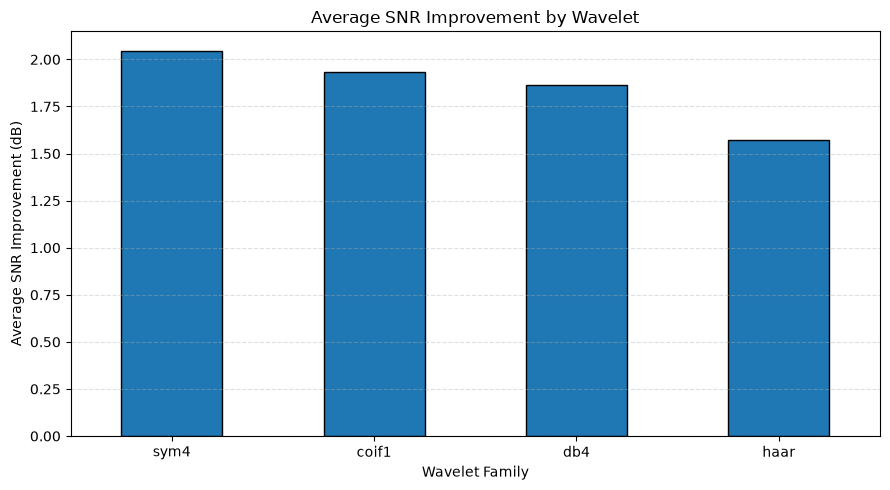

In [85]:
import matplotlib.pyplot as plt

# Compare average SNR improvement across wavelets
snr_comparison = summary_without_spike[
    "SNR_Improvement_dB"
].sort_values(ascending=False)

plt.figure(figsize=(9, 5))

snr_comparison.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Average SNR Improvement by Wavelet")
plt.xlabel("Wavelet Family")
plt.ylabel("Average SNR Improvement (dB)")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

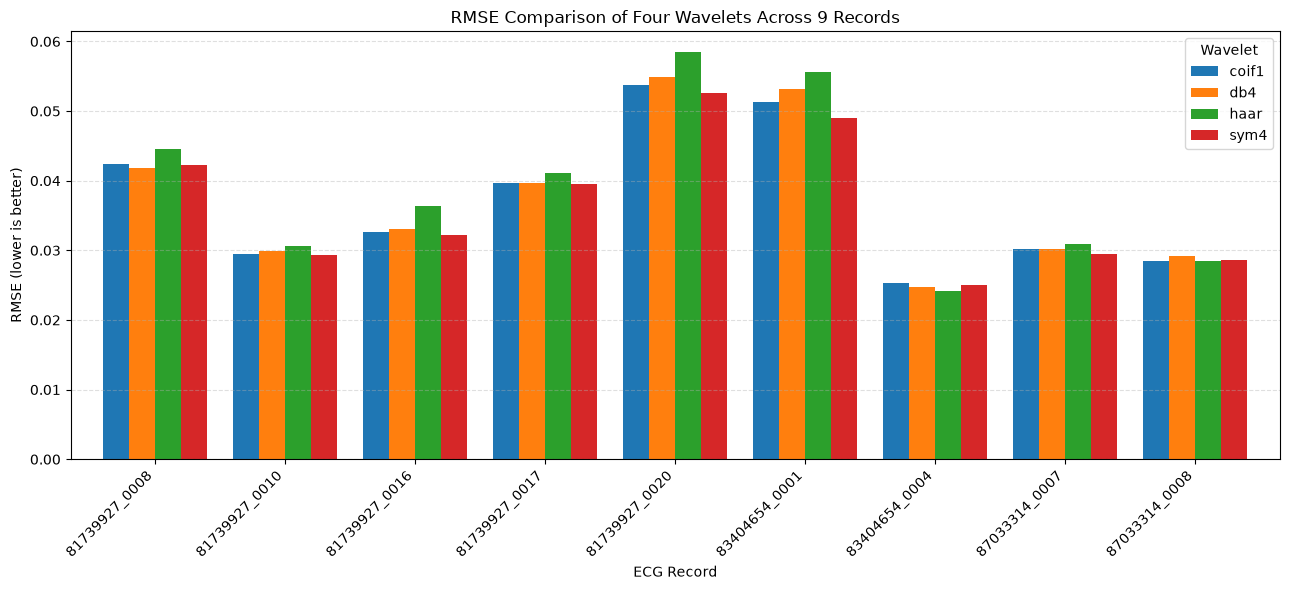

In [86]:
import matplotlib.pyplot as plt
import pandas as pd

# Exclude the flagged record only for this sensitivity comparison
plot_df = comparison_df[
    comparison_df["Record_ID"] != "81739927_0014"
].copy()

# Arrange RMSE values for each record and wavelet
rmse_pivot = plot_df.pivot(
    index="Record_ID",
    columns="Wavelet",
    values="RMSE"
)

# Plot grouped bar chart
rmse_pivot.plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

plt.title("RMSE Comparison of Four Wavelets Across 9 Records")
plt.xlabel("ECG Record")
plt.ylabel("RMSE (lower is better)")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Wavelet")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

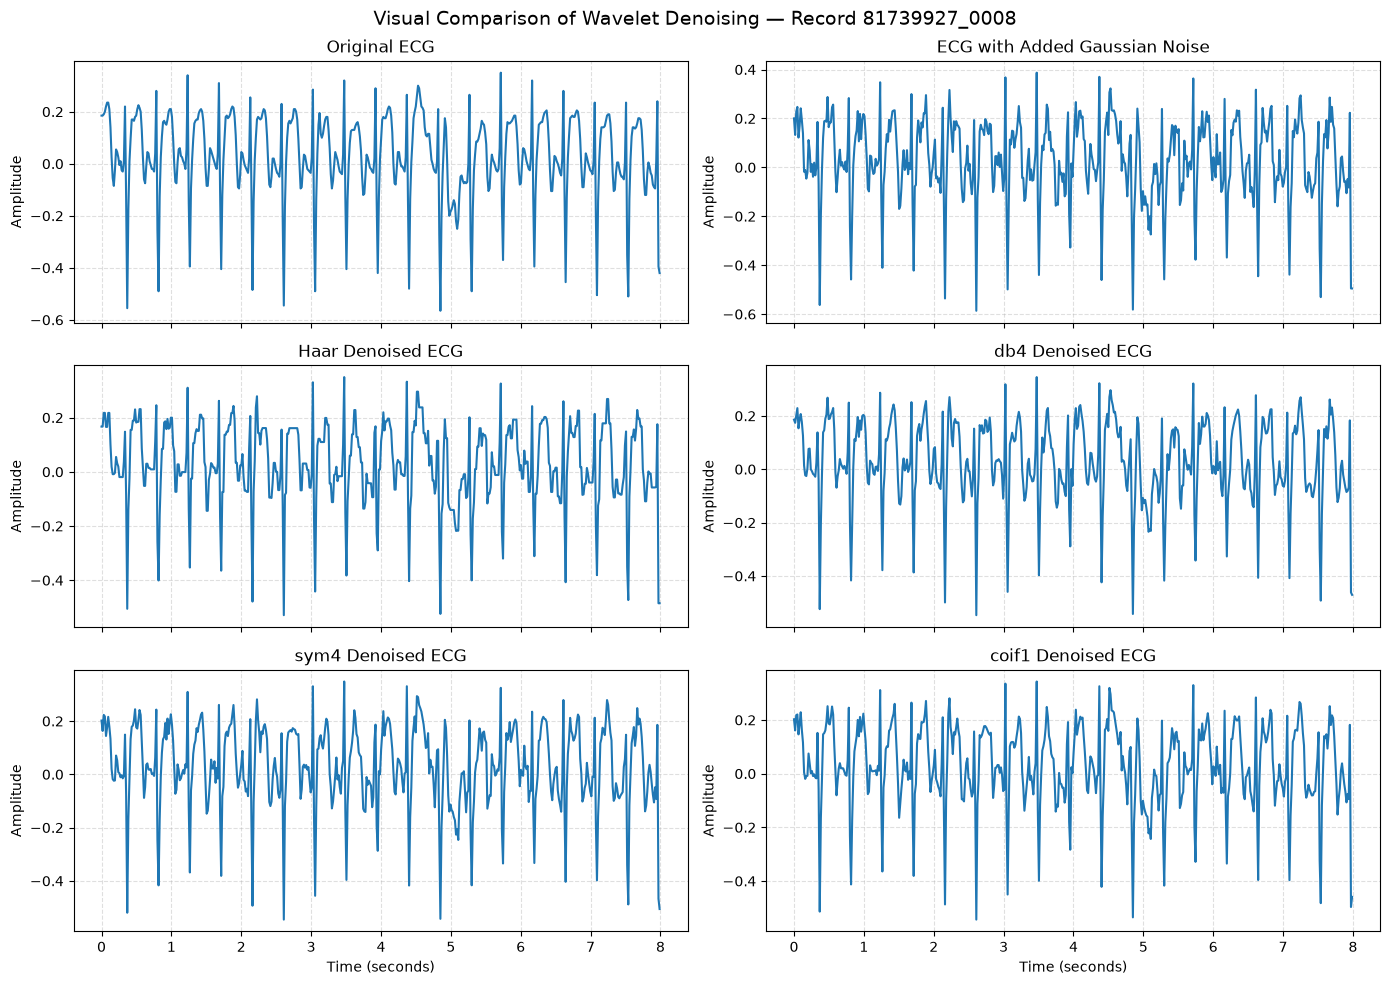

In [87]:
import matplotlib.pyplot as plt
import numpy as np

record_id = "81739927_0008"

original = noisy_records[record_id]["original"]
noisy = noisy_records[record_id]["noisy"]
fs = noisy_records[record_id]["fs"]

time = np.arange(len(original)) / fs

fig, axes = plt.subplots(3, 2, figsize=(14, 10), sharex=True)

signals_to_plot = [
    ("Original ECG", original),
    ("ECG with Added Gaussian Noise", noisy),
    ("Haar Denoised ECG", wavelet_results[record_id]["haar"]["denoised"]),
    ("db4 Denoised ECG", wavelet_results[record_id]["db4"]["denoised"]),
    ("sym4 Denoised ECG", wavelet_results[record_id]["sym4"]["denoised"]),
    ("coif1 Denoised ECG", wavelet_results[record_id]["coif1"]["denoised"])
]

for ax, (title, signal) in zip(axes.flat, signals_to_plot):
    ax.plot(time, signal)
    ax.set_title(title)
    ax.set_ylabel("Amplitude")
    ax.grid(True, linestyle="--", alpha=0.4)

for ax in axes[-1, :]:
    ax.set_xlabel("Time (seconds)")

fig.suptitle(
    "Visual Comparison of Wavelet Denoising — Record 81739927_0008",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [88]:
# Check existing PPG analysis variables

print("Available PPG-related variables:")

ppg_variables = [
    "loaded_records",
    "energy_results",
    "energy_df",
    "bayes_results",
    "bayes_df",
    "ppg",
    "ppg_coeffs",
    "ppg_energy"
]

for variable_name in ppg_variables:
    if variable_name in globals():
        variable = globals()[variable_name]

        print(
            f"{variable_name}: "
            f"{type(variable).__name__}"
        )
    else:
        print(f"{variable_name}: Not available")

Available PPG-related variables:
loaded_records: dict
energy_results: list
energy_df: DataFrame
bayes_results: list
bayes_df: DataFrame
ppg: ndarray
ppg_coeffs: list
ppg_energy: Not available


In [89]:
import pywt
import numpy as np
import pandas as pd

ppg_summary = []

for record_id, signals in loaded_records.items():

    ppg_signal = np.asarray(signals["ppg"], dtype=float)

    # Three-level Haar DWT
    coeffs = pywt.wavedec(
        ppg_signal,
        wavelet="haar",
        level=3
    )

    # Coefficients: approximation A3 and details D3, D2, D1
    A3, D3, D2, D1 = coeffs

    # Energy at each scale
    energies = {
        "A3_Energy": np.sum(A3 ** 2),
        "D3_Energy": np.sum(D3 ** 2),
        "D2_Energy": np.sum(D2 ** 2),
        "D1_Energy": np.sum(D1 ** 2)
    }

    total_energy = sum(energies.values())

    # Energy percentages
    row = {"Record_ID": record_id}

    for scale, energy in energies.items():
        row[scale] = energy
        row[scale.replace("_Energy", "_Percent")] = (
            100 * energy / total_energy
            if total_energy > 0 else np.nan
        )

    # Shannon entropy of normalized coefficient energy
    all_coeffs = np.concatenate(coeffs)
    probabilities = all_coeffs ** 2
    probabilities = probabilities / probabilities.sum()

    probabilities = probabilities[probabilities > 0]

    row["Coefficient_Energy_Entropy"] = -np.sum(
        probabilities * np.log2(probabilities)
    )

    ppg_summary.append(row)

ppg_energy_df = pd.DataFrame(ppg_summary)

print("Total PPG records analyzed:", len(ppg_energy_df))
display(ppg_energy_df.round(4))

Total PPG records analyzed: 10


,Record_ID,A3_Energy,A3_Percent,D3_Energy,D3_Percent,D2_Energy,D2_Percent,D1_Energy,D1_Percent,Coefficient_Energy_Entropy
0,81739927_0008,124.9117,99.7710,0.2097,0.1675,0.0606,0.0484,0.0165,0.0131,5.9563
1,81739927_0010,104.1783,97.9502,1.6117,1.5153,0.4482,0.4214,0.1203,0.1131,5.7754
2,81739927_0014,137.3260,99.5082,0.4630,0.3355,0.1577,0.1143,0.0579,0.0420,5.7831
3,81739927_0016,100.9251,99.1363,0.6022,0.5915,0.2202,0.2163,0.0568,0.0558,5.8694
4,81739927_0017,89.2481,99.0275,0.6271,0.6958,0.1963,0.2179,0.0530,0.0588,5.9007
5,81739927_0020,122.8558,99.1824,0.7251,0.5854,0.2172,0.1753,0.0705,0.0569,5.7188
6,87033314_0007,126.2346,98.6233,1.3116,1.0247,0.3571,0.2790,0.0934,0.0730,5.8494
7,87033314_0008,95.7259,99.5283,0.3075,0.3197,0.1235,0.1284,0.0227,0.0236,5.7649
8,83404654_0001,271.0089,99.9700,0.0595,0.0220,0.0170,0.0063,0.0050,0.0018,5.9434
9,83404654_0004,136.5451,99.9025,0.0967,0.0707,0.0289,0.0211,0.0078,0.0057,5.9353


In [90]:
# Verify that relative energy percentages sum to approximately 100%

percentage_columns = [
    "A3_Percent",
    "D3_Percent",
    "D2_Percent",
    "D1_Percent"
]

ppg_energy_df["Total_Energy_Percent"] = (
    ppg_energy_df[percentage_columns].sum(axis=1)
)

display(
    ppg_energy_df[
        ["Record_ID", "Total_Energy_Percent"]
    ].round(4)
)

,Record_ID,Total_Energy_Percent
0,81739927_0008,100.0
1,81739927_0010,100.0
2,81739927_0014,100.0
3,81739927_0016,100.0
4,81739927_0017,100.0
5,81739927_0020,100.0
6,87033314_0007,100.0
7,87033314_0008,100.0
8,83404654_0001,100.0
9,83404654_0004,100.0


In [91]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Check ECG energy table columns first
print("ECG energy table columns:")
print(energy_df.columns.tolist())

print("\nPPG energy table columns:")
print(ppg_energy_df.columns.tolist())

ECG energy table columns:
['Record_ID', 'D1_Energy', 'D1_Relative_Percent', 'D2_Energy', 'D2_Relative_Percent', 'D3_Energy', 'D3_Relative_Percent', 'A3_Energy', 'A3_Relative_Percent']

PPG energy table columns:
['Record_ID', 'A3_Energy', 'A3_Percent', 'D3_Energy', 'D3_Percent', 'D2_Energy', 'D2_Percent', 'D1_Energy', 'D1_Percent', 'Coefficient_Energy_Entropy', 'Total_Energy_Percent']


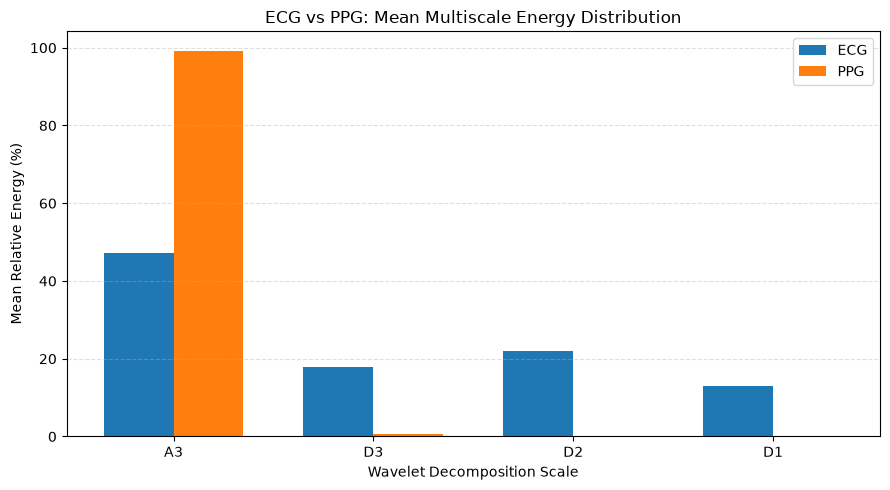

,Scale,ECG_Mean_Energy_Percent,PPG_Mean_Energy_Percent
0,A3,47.2542,99.2600
1,D3,17.7501,0.5328
2,D2,21.9076,0.1628
3,D1,13.0882,0.0444


In [92]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Merge ECG and PPG energy results using Record_ID
energy_comparison = pd.merge(
    energy_df,
    ppg_energy_df,
    on="Record_ID",
    suffixes=("_ECG", "_PPG")
)

# Columns to compare
ecg_columns = [
    "A3_Relative_Percent",
    "D3_Relative_Percent",
    "D2_Relative_Percent",
    "D1_Relative_Percent"
]

ppg_columns = [
    "A3_Percent",
    "D3_Percent",
    "D2_Percent",
    "D1_Percent"
]

scales = ["A3", "D3", "D2", "D1"]

# Calculate mean energy percentage across 10 records
ecg_mean = [
    energy_comparison[col].mean()
    for col in ecg_columns
]

ppg_mean = [
    energy_comparison[col].mean()
    for col in ppg_columns
]

# Grouped bar chart
x = np.arange(len(scales))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    ecg_mean,
    width,
    label="ECG"
)

plt.bar(
    x + width / 2,
    ppg_mean,
    width,
    label="PPG"
)

plt.xticks(x, scales)
plt.xlabel("Wavelet Decomposition Scale")
plt.ylabel("Mean Relative Energy (%)")
plt.title("ECG vs PPG: Mean Multiscale Energy Distribution")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# Print numerical comparison
energy_mean_df = pd.DataFrame({
    "Scale": scales,
    "ECG_Mean_Energy_Percent": ecg_mean,
    "PPG_Mean_Energy_Percent": ppg_mean
})

display(energy_mean_df.round(4))

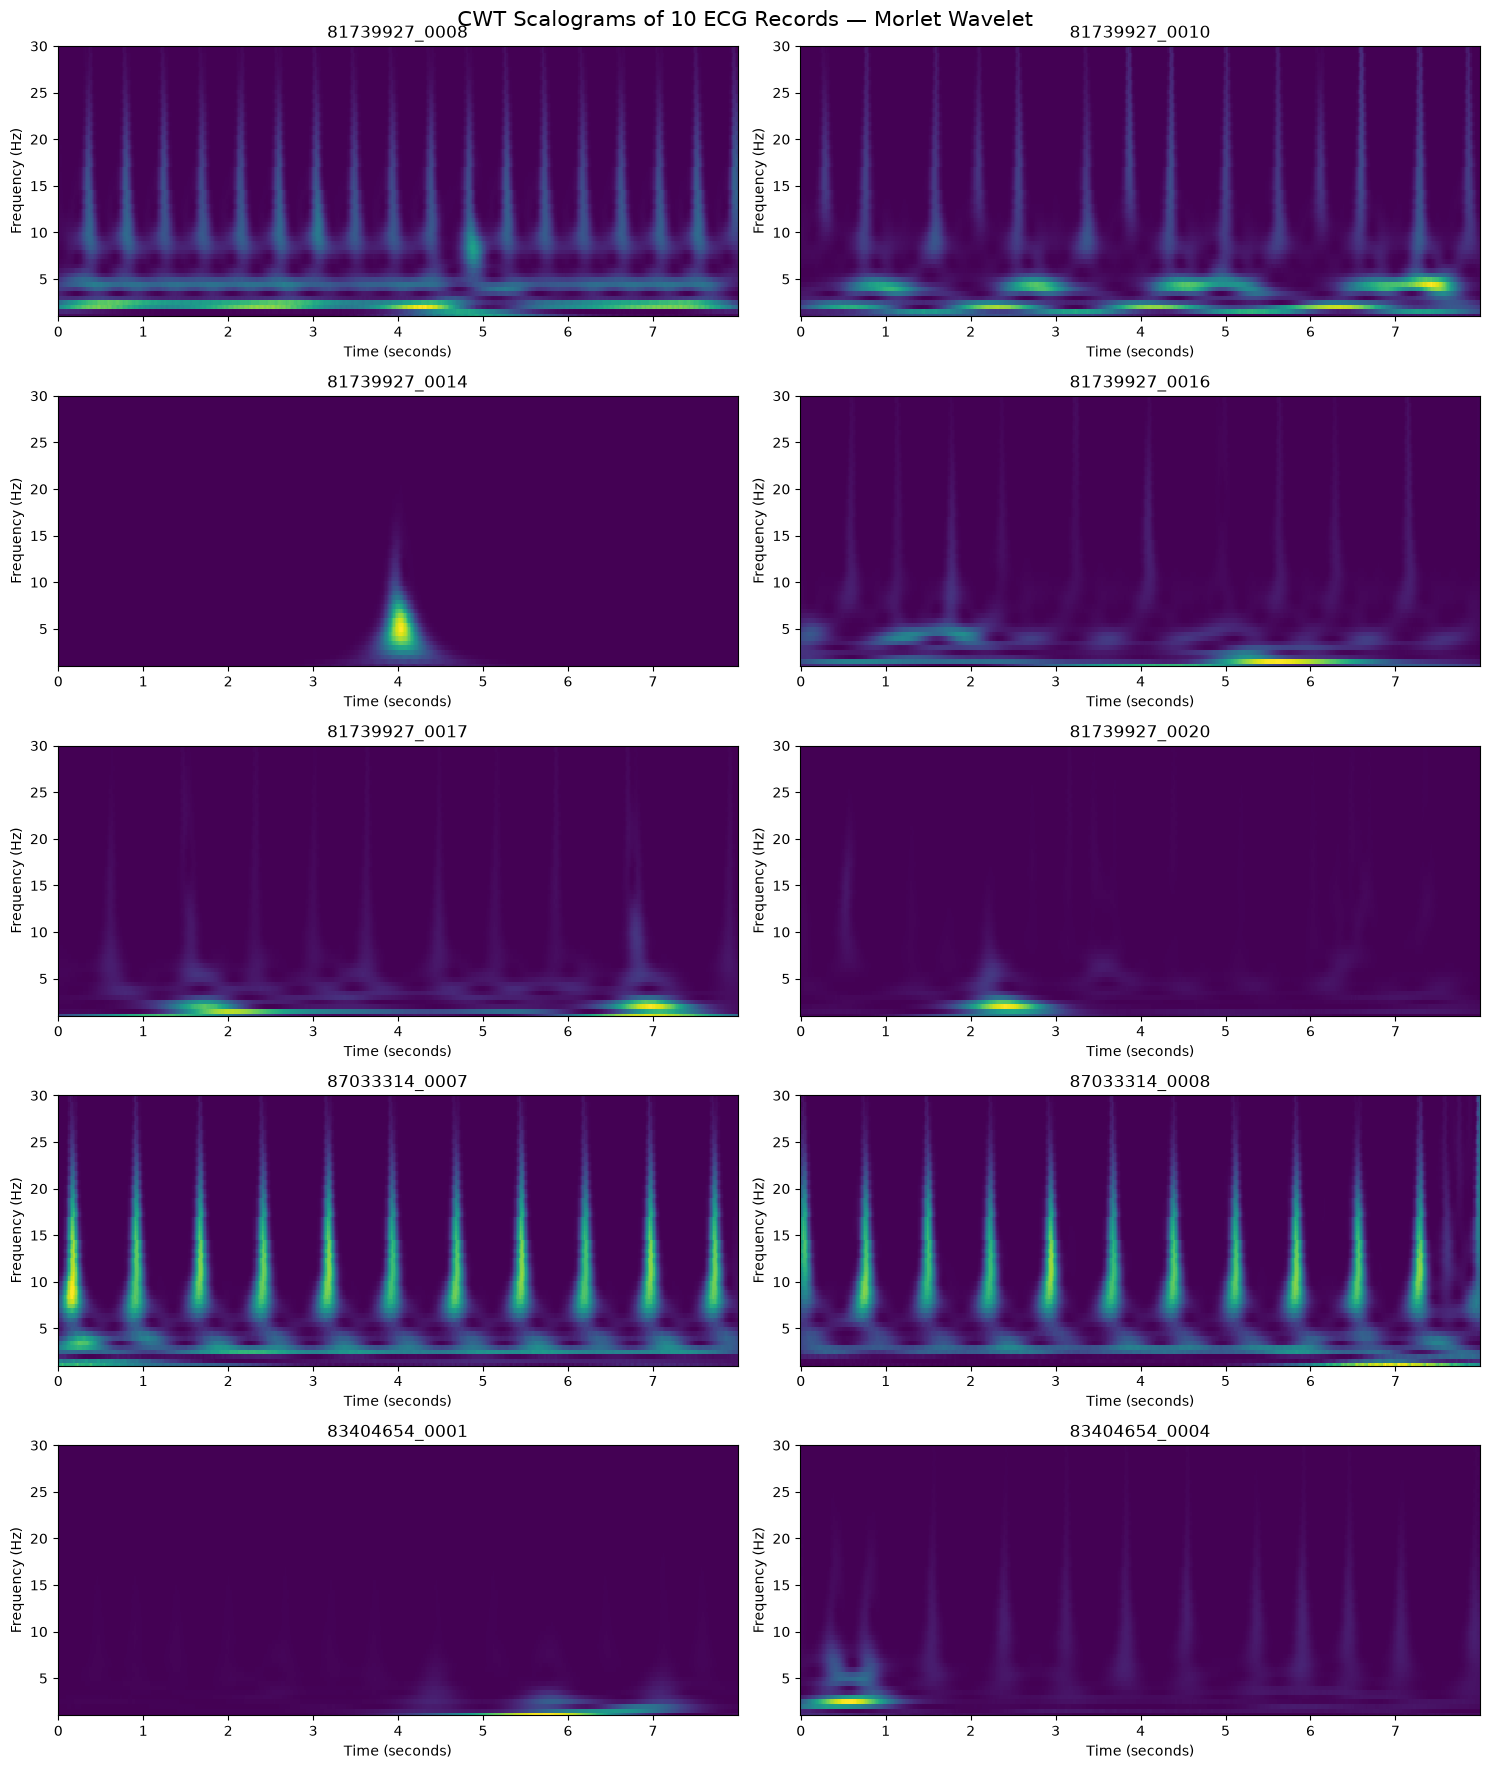

In [93]:
import numpy as np
import matplotlib.pyplot as plt
import pywt

# CWT settings
wavelet_name = "cmor1.5-1.0"
frequency_range = np.linspace(1, 30, 60)

# Create 10 scalograms
fig, axes = plt.subplots(5, 2, figsize=(15, 18))

for ax, (record_id, signals) in zip(
    axes.flat, loaded_records.items()
):
    ecg_signal = np.asarray(signals["ecg"], dtype=float)
    fs = signals["fs"]

    # Convert desired frequencies into wavelet scales
    scales = pywt.central_frequency(wavelet_name) * fs / frequency_range

    # Continuous Wavelet Transform
    coefficients, frequencies = pywt.cwt(
        ecg_signal,
        scales,
        wavelet_name,
        sampling_period=1 / fs
    )

    # Scalogram power
    power = np.abs(coefficients) ** 2

    time = np.arange(len(ecg_signal)) / fs

    ax.pcolormesh(
        time,
        frequencies,
        power,
        shading="auto"
    )

    ax.set_title(record_id)
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Frequency (Hz)")
    ax.set_ylim(1, 30)

fig.suptitle(
    "CWT Scalograms of 10 ECG Records — Morlet Wavelet",
    fontsize=15
)

plt.tight_layout()
plt.show()

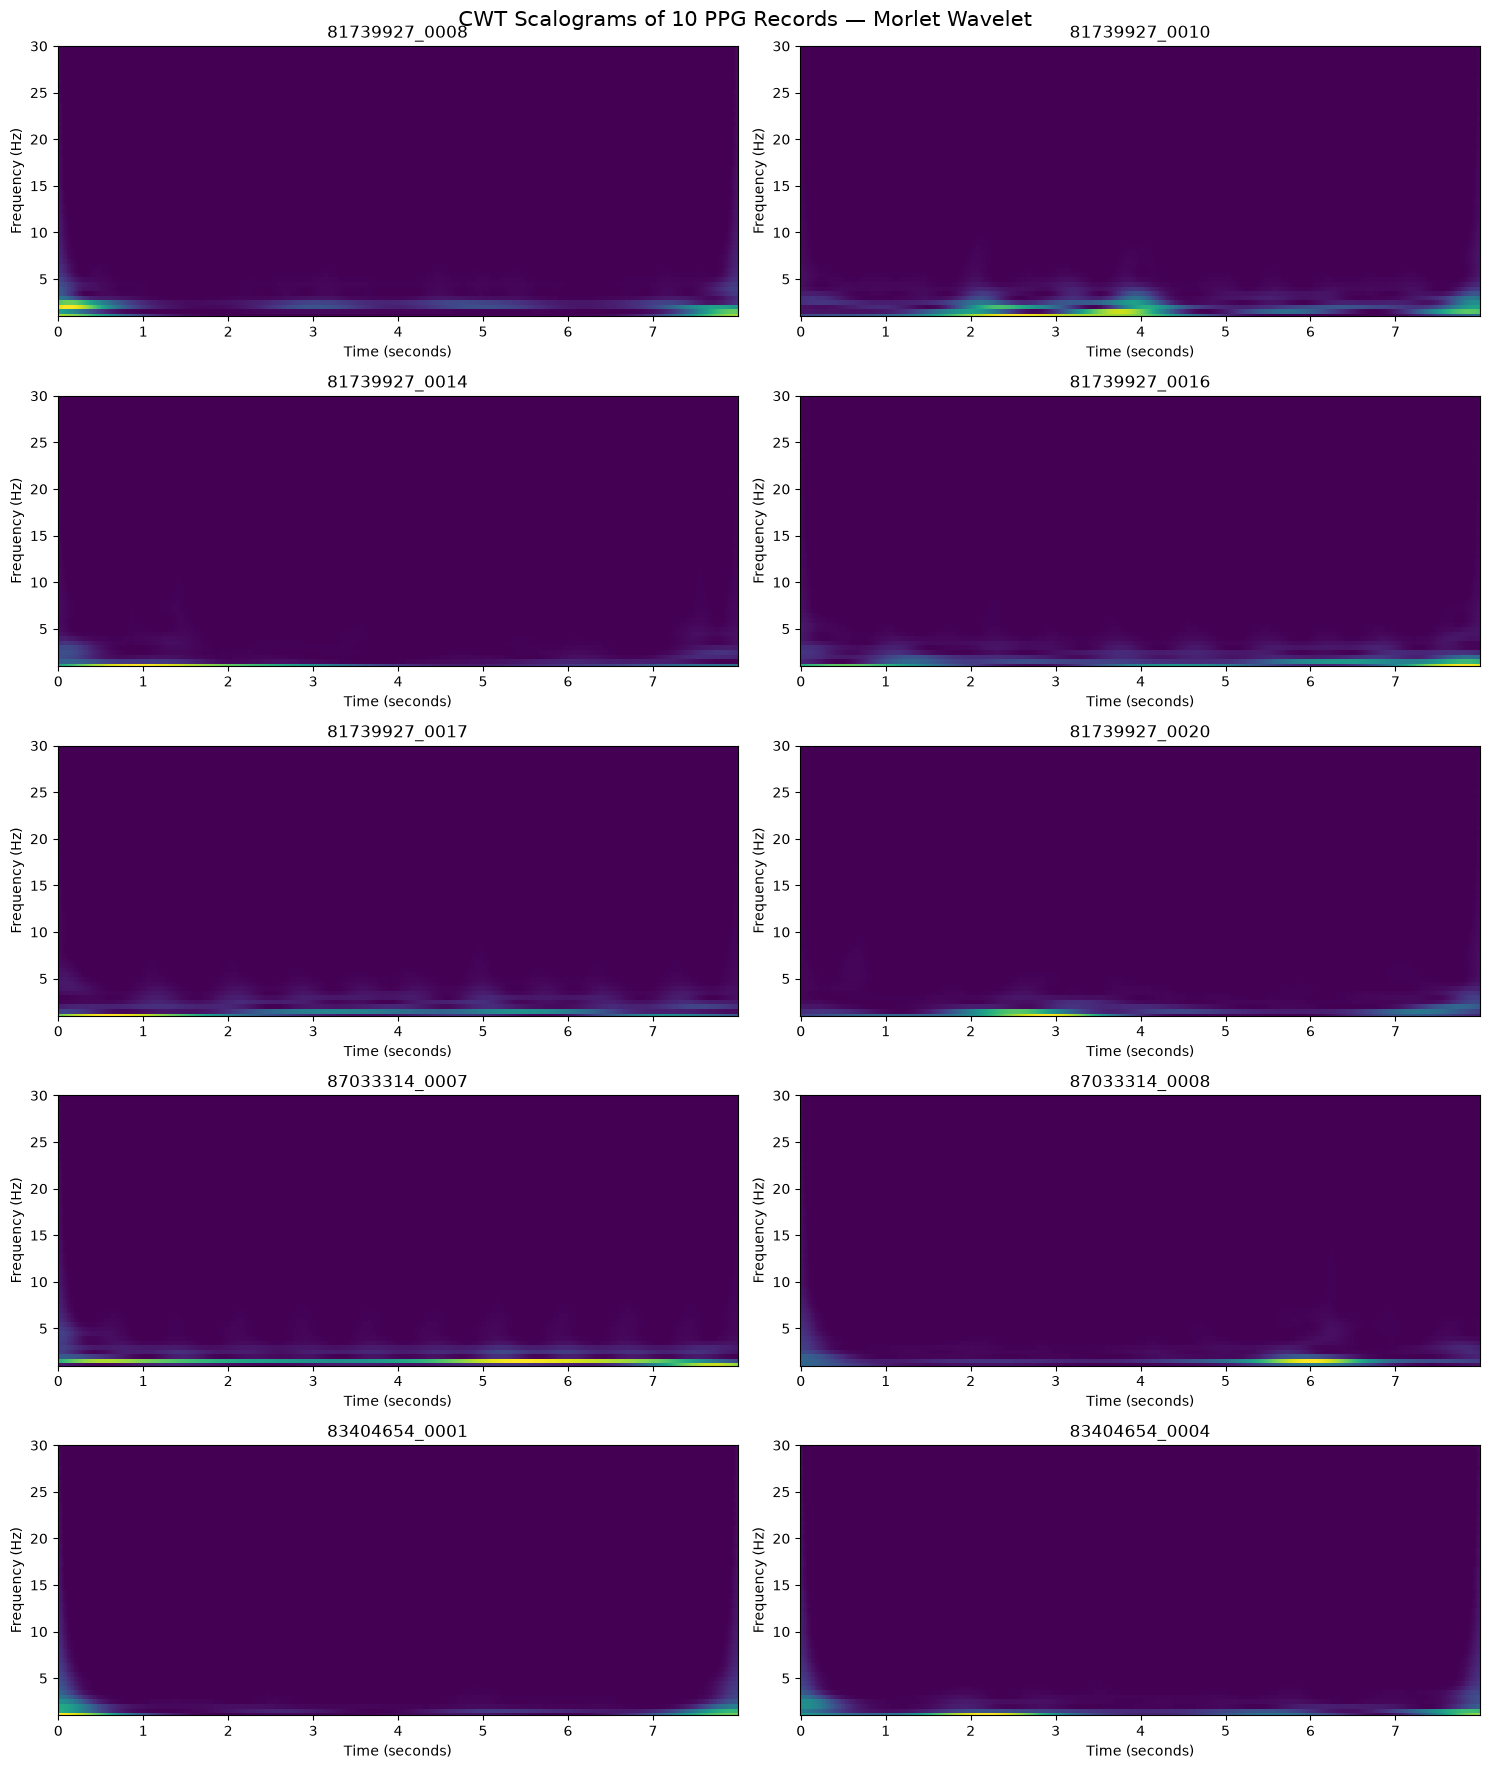

In [94]:
import numpy as np
import matplotlib.pyplot as plt
import pywt

# CWT configuration
wavelet_name = "cmor1.5-1.0"
frequency_range = np.linspace(1, 30, 60)

fig, axes = plt.subplots(5, 2, figsize=(15, 18))

for ax, (record_id, signals) in zip(
    axes.flat, loaded_records.items()
):
    ppg_signal = np.asarray(signals["ppg"], dtype=float)
    fs = signals["fs"]

    # Convert frequencies into wavelet scales
    scales = (
        pywt.central_frequency(wavelet_name)
        * fs
        / frequency_range
    )

    # Continuous Wavelet Transform
    coefficients, frequencies = pywt.cwt(
        ppg_signal,
        scales,
        wavelet_name,
        sampling_period=1 / fs
    )

    # CWT coefficient power
    power = np.abs(coefficients) ** 2

    time = np.arange(len(ppg_signal)) / fs

    ax.pcolormesh(
        time,
        frequencies,
        power,
        shading="auto"
    )

    ax.set_title(record_id)
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Frequency (Hz)")
    ax.set_ylim(1, 30)

fig.suptitle(
    "CWT Scalograms of 10 PPG Records — Morlet Wavelet",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [95]:
import numpy as np
import pandas as pd
import pywt

entropy_results = []

for record_id, signals in loaded_records.items():

    row = {"Record_ID": record_id}

    for signal_name in ["ecg", "ppg"]:

        signal = np.asarray(
            signals[signal_name],
            dtype=float
        )

        # Three-level Haar DWT
        coeffs = pywt.wavedec(
            signal,
            wavelet="haar",
            level=3
        )

        # Combine approximation and detail coefficients
        all_coeffs = np.concatenate(coeffs)

        # Normalize squared coefficients into probabilities
        energy = all_coeffs ** 2
        total_energy = np.sum(energy)

        if total_energy > 0:
            probabilities = energy / total_energy
            probabilities = probabilities[probabilities > 0]

            entropy = -np.sum(
                probabilities * np.log2(probabilities)
            )
        else:
            entropy = np.nan

        row[f"{signal_name.upper()}_Energy_Entropy"] = entropy

    entropy_results.append(row)

entropy_df = pd.DataFrame(entropy_results)

print("Entropy results for all records:")
display(entropy_df.round(4))

Entropy results for all records:


,Record_ID,ECG_Energy_Entropy,PPG_Energy_Entropy
0,81739927_0008,6.8967,5.9563
1,81739927_0010,7.0848,5.7754
2,81739927_0014,2.9151,5.7831
3,81739927_0016,6.7615,5.8694
4,81739927_0017,6.3489,5.9007
5,81739927_0020,5.7607,5.7188
6,87033314_0007,6.3489,5.8494
7,87033314_0008,6.5901,5.7649
8,83404654_0001,5.1373,5.9434
9,83404654_0004,6.2708,5.9353


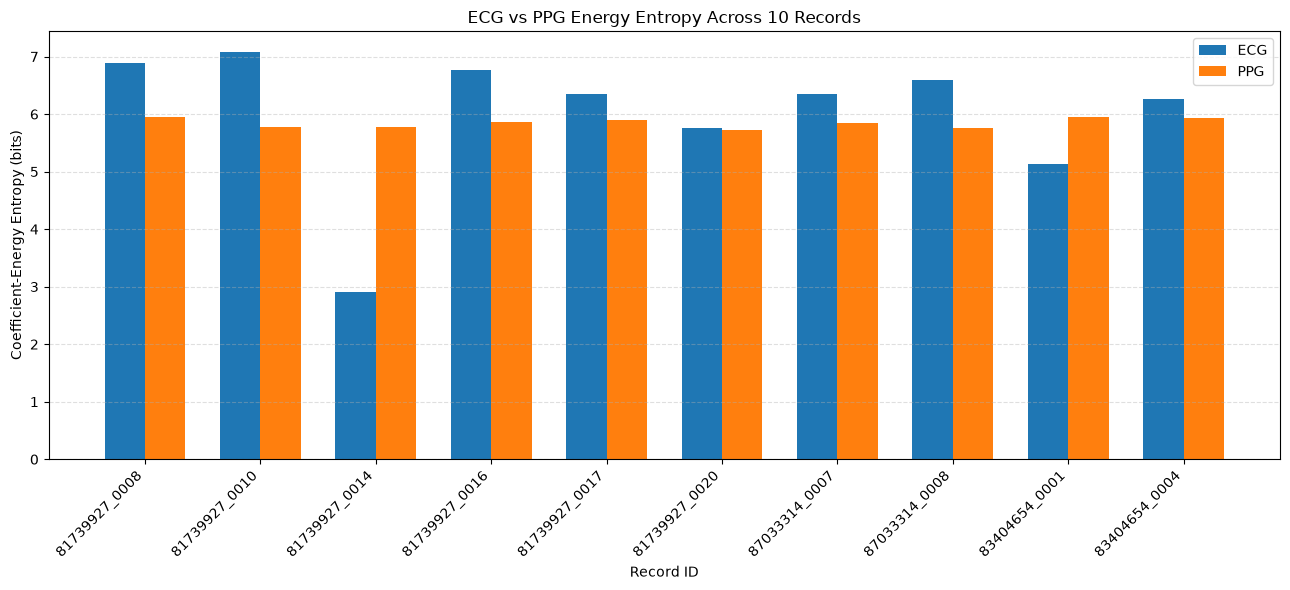

In [96]:
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(entropy_df))
width = 0.35

plt.figure(figsize=(13, 6))

plt.bar(
    x - width / 2,
    entropy_df["ECG_Energy_Entropy"],
    width,
    label="ECG"
)

plt.bar(
    x + width / 2,
    entropy_df["PPG_Energy_Entropy"],
    width,
    label="PPG"
)

plt.xticks(
    x,
    entropy_df["Record_ID"],
    rotation=45,
    ha="right"
)

plt.xlabel("Record ID")
plt.ylabel("Coefficient-Energy Entropy (bits)")
plt.title("ECG vs PPG Energy Entropy Across 10 Records")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [97]:
import numpy as np
import pandas as pd
from scipy.signal import find_peaks

morphology_results = []

for record_id, signals in loaded_records.items():

    original = np.asarray(signals["ecg"], dtype=float)

    # Retrieve BayesShrink-denoised ECG for this record
    result = next(
        item for item in bayes_results
        if item["Record_ID"] == record_id
    )

    denoised = np.asarray(
        result["Denoised_ECG"],
        dtype=float
    )

    # Ensure both signals have matching lengths
    n = min(len(original), len(denoised))
    original = original[:n]
    denoised = denoised[:n]

    fs = signals["fs"]

    # Detect prominent downward ECG peaks
    min_distance = max(1, int(0.30 * fs))

    original_peaks, _ = find_peaks(
        -original,
        distance=min_distance,
        prominence=0.05
    )

    denoised_peaks, _ = find_peaks(
        -denoised,
        distance=min_distance,
        prominence=0.05
    )

    # Correlation between original and denoised waveform
    if np.std(original) > 0 and np.std(denoised) > 0:
        correlation = np.corrcoef(
            original, denoised
        )[0, 1]
    else:
        correlation = np.nan

    morphology_results.append({
        "Record_ID": record_id,
        "Original_Peak_Count": len(original_peaks),
        "Denoised_Peak_Count": len(denoised_peaks),
        "Peak_Count_Difference": (
            len(denoised_peaks) - len(original_peaks)
        ),
        "Waveform_Correlation": correlation
    })

morphology_df = pd.DataFrame(morphology_results)

display(morphology_df.round(4))

KeyError: 'Denoised_ECG'

In [98]:
# Inspect the structure of the first BayesShrink result

print("Number of results:", len(bayes_results))

print("\nFirst result type:")
print(type(bayes_results[0]))

print("\nKeys in the first result:")
print(bayes_results[0].keys())

print("\nFirst result details:")
for key, value in bayes_results[0].items():
    if isinstance(value, np.ndarray):
        print(key, "| Type:", type(value).__name__,
              "| Shape:", value.shape)
    else:
        print(key, "| Value:", value)

Number of results: 10

First result type:
<class 'dict'>

Keys in the first result:
dict_keys(['Record_ID', 'Noise_Sigma', 'D1_Threshold', 'D2_Threshold', 'D3_Threshold', 'RMSE', 'MAE', 'NRMSE', 'PRD_Percent', 'Correlation'])

First result details:
Record_ID | Value: 81739927_0008
Noise_Sigma | Value: 0.03145026454499101
D1_Threshold | Value: 0.012961443298601858
D2_Threshold | Value: 0.005216616887909737
D3_Threshold | Value: 0.006860488829936242
RMSE | Value: 0.008492664005755327
MAE | Value: 0.007557018884438651
NRMSE | Value: 0.009281600006289976
PRD_Percent | Value: 5.340152306986278
Correlation | Value: 0.9987531630733859


In [99]:
# Check whether wavelet_results exists
if "wavelet_results" in globals():

    print("wavelet_results type:", type(wavelet_results))
    print("Number of records:", len(wavelet_results))

    # Inspect the first record
    first_record_id = next(iter(wavelet_results))

    print("\nFirst record ID:", first_record_id)
    print("Available keys:", wavelet_results[first_record_id].keys())

    # Inspect Haar result
    if "haar" in wavelet_results[first_record_id]:
        print(
            "\nHaar result keys:",
            wavelet_results[first_record_id]["haar"].keys()
        )

else:
    print("wavelet_results is not available.")

wavelet_results type: <class 'dict'>
Number of records: 10

First record ID: 81739927_0008
Available keys: dict_keys(['haar', 'db4', 'sym4', 'coif1'])

Haar result keys: dict_keys(['denoised', 'estimated_sigma'])


In [100]:
import numpy as np
import pandas as pd
from scipy.signal import find_peaks

morphology_results = []

for record_id, signals in loaded_records.items():

    original = np.asarray(signals["ecg"], dtype=float)

    # BayesShrink result using the existing wavelet output
    denoised = np.asarray(
        wavelet_results[record_id]["sym4"]["denoised"],
        dtype=float
    )

    # Make lengths equal before calculating metrics
    n = min(len(original), len(denoised))
    original = original[:n]
    denoised = denoised[:n]

    fs = signals["fs"]

    # Detect prominent downward peaks in the ECG
    min_distance = max(1, int(0.30 * fs))

    original_peaks, _ = find_peaks(
        -original,
        distance=min_distance,
        prominence=0.05
    )

    denoised_peaks, _ = find_peaks(
        -denoised,
        distance=min_distance,
        prominence=0.05
    )

    # Correlation between the original and denoised waveforms
    if np.std(original) > 0 and np.std(denoised) > 0:
        correlation = np.corrcoef(
            original,
            denoised
        )[0, 1]
    else:
        correlation = np.nan

    morphology_results.append({
        "Record_ID": record_id,
        "Original_Peak_Count": len(original_peaks),
        "Denoised_Peak_Count": len(denoised_peaks),
        "Peak_Count_Difference": (
            len(denoised_peaks) - len(original_peaks)
        ),
        "Waveform_Correlation": correlation
    })

morphology_df = pd.DataFrame(morphology_results)

display(morphology_df.round(4))

,Record_ID,Original_Peak_Count,Denoised_Peak_Count,Peak_Count_Difference,Waveform_Correlation
0,81739927_0008,18,19,1,0.9627
1,81739927_0010,18,17,-1,0.9633
2,81739927_0014,9,19,10,0.9756
3,81739927_0016,18,18,0,0.9697
4,81739927_0017,18,20,2,0.9718
5,81739927_0020,19,21,2,0.9658
6,87033314_0007,21,21,0,0.9695
7,87033314_0008,21,21,0,0.9637
8,83404654_0001,13,16,3,0.9790
9,83404654_0004,15,19,4,0.9633


In [101]:
import numpy as np
import pandas as pd
import pywt

from scipy.signal import butter, sosfiltfilt

comparison_results = []

for record_id, signals in loaded_records.items():

    original = np.asarray(signals["ecg"], dtype=float)
    fs = signals["fs"]

    # 1. Butterworth bandpass filtering
    sos = butter(
        4,
        [0.5, 30],
        btype="bandpass",
        fs=fs,
        output="sos"
    )

    butterworth_signal = sosfiltfilt(sos, original)

    # 2. Retrieve existing sym4-denoised signal
    wavelet_signal = np.asarray(
        wavelet_results[record_id]["sym4"]["denoised"],
        dtype=float
    )

    # Match lengths
    n = min(
        len(original),
        len(butterworth_signal),
        len(wavelet_signal)
    )

    original = original[:n]
    butterworth_signal = butterworth_signal[:n]
    wavelet_signal = wavelet_signal[:n]

    def calculate_metrics(reference, processed):
        error = reference - processed

        rmse = np.sqrt(np.mean(error ** 2))
        mae = np.mean(np.abs(error))

        signal_range = np.max(reference) - np.min(reference)
        nrmse = rmse / signal_range if signal_range > 0 else np.nan

        reference_energy = np.sum(reference ** 2)
        prd = (
            100 * np.sqrt(np.sum(error ** 2) / reference_energy)
            if reference_energy > 0 else np.nan
        )

        corr = (
            np.corrcoef(reference, processed)[0, 1]
            if np.std(reference) > 0 and np.std(processed) > 0
            else np.nan
        )

        return rmse, mae, nrmse, prd, corr

    for method, processed in [
        ("Butterworth", butterworth_signal),
        ("Symlet-4", wavelet_signal)
    ]:
        rmse, mae, nrmse, prd, corr = calculate_metrics(
            original, processed
        )

        comparison_results.append({
            "Record_ID": record_id,
            "Method": method,
            "RMSE": rmse,
            "MAE": mae,
            "NRMSE": nrmse,
            "PRD_Percent": prd,
            "Correlation": corr
        })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(4))

,Record_ID,Method,RMSE,MAE,NRMSE,PRD_Percent,Correlation
0,81739927_0008,Butterworth,0.0949,0.0592,0.1037,59.6771,0.8474
1,81739927_0008,Symlet-4,0.0423,0.0333,0.0462,26.5683,0.9627
2,81739927_0010,Butterworth,0.0287,0.0214,0.0372,26.2951,0.9661
3,81739927_0010,Symlet-4,0.0293,0.0222,0.0381,26.8917,0.9633
4,81739927_0014,Butterworth,0.4500,0.2594,0.0072,11.5770,0.9939
5,81739927_0014,Symlet-4,0.8584,0.6283,0.0137,22.0840,0.9756
6,81739927_0016,Butterworth,0.0399,0.0248,0.0512,30.9663,0.9529
7,81739927_0016,Symlet-4,0.0322,0.0244,0.0413,24.9986,0.9697
8,81739927_0017,Butterworth,0.0175,0.0147,0.0144,10.6260,0.9951
9,81739927_0017,Symlet-4,0.0395,0.0307,0.0325,24.0517,0.9718


In [102]:
import numpy as np
import pandas as pd
import pywt
from scipy.signal import butter, sosfiltfilt

controlled_results = []

for record_id, signals in loaded_records.items():

    # Treat the recorded ECG as the reference for this experiment
    reference = np.asarray(signals["ecg"], dtype=float)
    fs = signals["fs"]

    # Reproducible Gaussian noise targeting 10 dB SNR
    rng = np.random.default_rng(42)

    signal_power = np.mean(reference ** 2)
    noise_power = signal_power / (10 ** (10 / 10))
    noise = rng.normal(
        0,
        np.sqrt(noise_power),
        size=len(reference)
    )

    noisy_signal = reference + noise

    # Method 1: Butterworth bandpass filtering
    sos = butter(
        4,
        [0.5, 30],
        btype="bandpass",
        fs=fs,
        output="sos"
    )

    butterworth_output = sosfiltfilt(sos, noisy_signal)

    # Method 2: Symlet-4 wavelet denoising
    wavelet = "sym4"
    level = 3

    coeffs = pywt.wavedec(
        noisy_signal,
        wavelet,
        level=level
    )

    detail_coeffs = coeffs[1:]
    finest_detail = detail_coeffs[-1]

    sigma = (
        np.median(np.abs(finest_detail))
        / 0.6745
    )

    threshold = sigma * np.sqrt(
        2 * np.log(len(noisy_signal))
    )

    denoised_coeffs = [coeffs[0]]

    for detail in detail_coeffs:
        denoised_coeffs.append(
            pywt.threshold(
                detail,
                threshold,
                mode="soft"
            )
        )

    sym4_output = pywt.waverec(
        denoised_coeffs,
        wavelet
    )[:len(reference)]

    # Calculate metrics against the known reference
    for method, processed in [
        ("Butterworth", butterworth_output),
        ("Symlet-4", sym4_output)
    ]:

        error = reference - processed

        rmse = np.sqrt(np.mean(error ** 2))
        mae = np.mean(np.abs(error))

        signal_range = np.ptp(reference)
        nrmse = (
            rmse / signal_range
            if signal_range > 0 else np.nan
        )

        reference_energy = np.sum(reference ** 2)
        prd = (
            100 * np.sqrt(
                np.sum(error ** 2) / reference_energy
            )
            if reference_energy > 0 else np.nan
        )

        correlation = (
            np.corrcoef(reference, processed)[0, 1]
            if np.std(reference) > 0
            and np.std(processed) > 0
            else np.nan
        )

        controlled_results.append({
            "Record_ID": record_id,
            "Method": method,
            "RMSE": rmse,
            "MAE": mae,
            "NRMSE": nrmse,
            "PRD_Percent": prd,
            "Correlation": correlation
        })

controlled_comparison_df = pd.DataFrame(
    controlled_results
)

display(controlled_comparison_df.round(4))

,Record_ID,Method,RMSE,MAE,NRMSE,PRD_Percent,Correlation
0,81739927_0008,Butterworth,0.1173,0.0785,0.1282,73.7814,0.7833
1,81739927_0008,Symlet-4,0.0910,0.0619,0.0994,57.2056,0.8211
2,81739927_0010,Butterworth,0.0403,0.0315,0.0523,36.9788,0.9364
3,81739927_0010,Symlet-4,0.0549,0.0414,0.0713,50.3604,0.8771
4,81739927_0014,Butterworth,1.2845,1.0180,0.0206,33.0478,0.9490
5,81739927_0014,Symlet-4,0.7122,0.4453,0.0114,18.3238,0.9839
6,81739927_0016,Butterworth,0.0617,0.0441,0.0791,47.8922,0.8946
7,81739927_0016,Symlet-4,0.0544,0.0405,0.0698,42.2184,0.9087
8,81739927_0017,Butterworth,0.0545,0.0430,0.0448,33.1452,0.9485
9,81739927_0017,Symlet-4,0.0603,0.0417,0.0496,36.6918,0.9329


In [103]:
# Step 17: Average performance comparison

summary_df = (
    controlled_comparison_df
    .groupby("Method")[
        ["RMSE", "MAE", "NRMSE", "PRD_Percent", "Correlation"]
    ]
    .mean()
    .reset_index()
)

display(summary_df.round(4))

,Method,RMSE,MAE,NRMSE,PRD_Percent,Correlation
0,Butterworth,0.2002,0.1536,0.0681,51.9425,0.8723
1,Symlet-4,0.1291,0.0847,0.0556,42.1550,0.9032


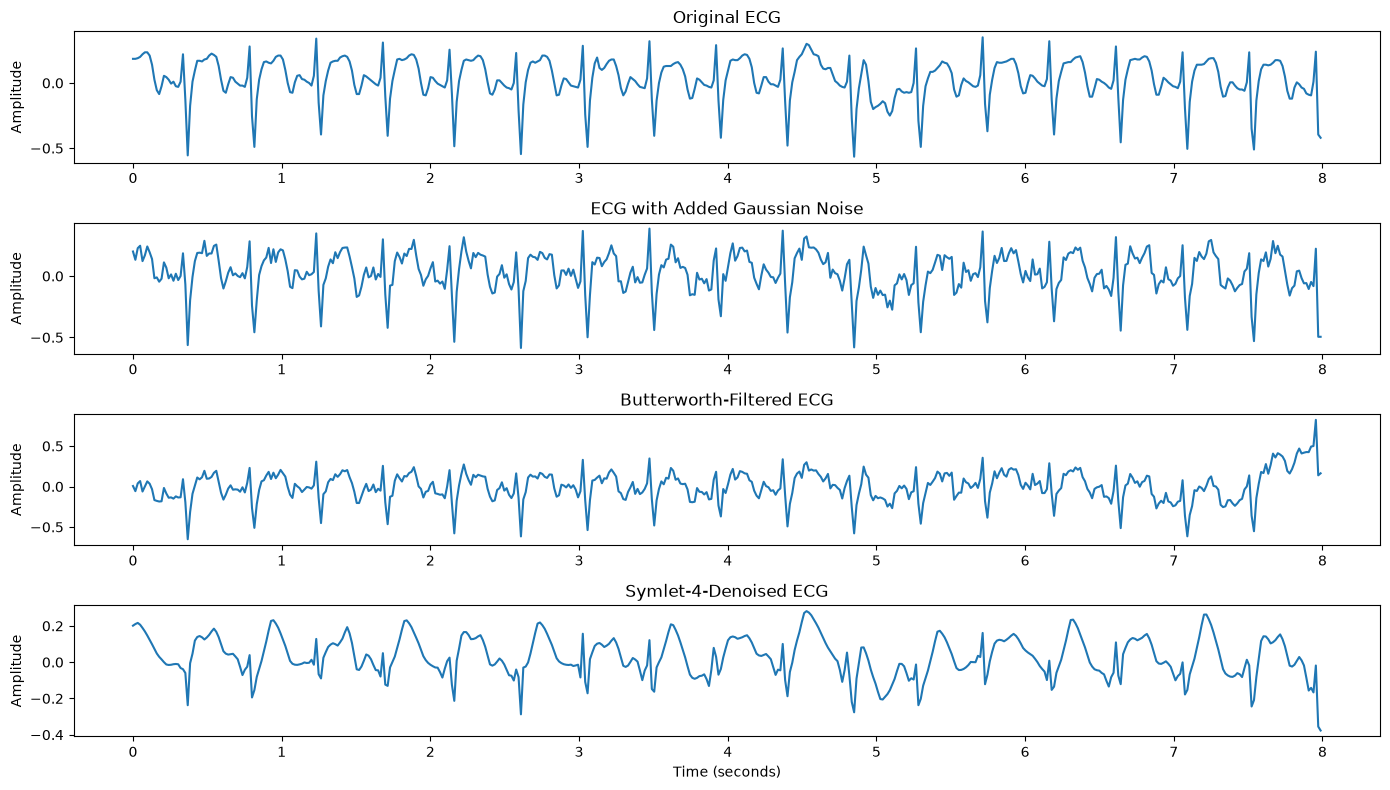

In [104]:
import numpy as np
import matplotlib.pyplot as plt
import pywt
from scipy.signal import butter, sosfiltfilt

# Choose a representative record
record_id = "81739927_0008"

reference = np.asarray(
    loaded_records[record_id]["ecg"],
    dtype=float
)

fs = loaded_records[record_id]["fs"]

# Recreate the controlled Gaussian noise
rng = np.random.default_rng(42)

signal_power = np.mean(reference ** 2)
noise_power = signal_power / (10 ** (10 / 10))

noise = rng.normal(
    0,
    np.sqrt(noise_power),
    size=len(reference)
)

noisy_signal = reference + noise

# Butterworth filtering
sos = butter(
    4,
    [0.5, 30],
    btype="bandpass",
    fs=fs,
    output="sos"
)

butterworth_output = sosfiltfilt(sos, noisy_signal)

# Symlet-4 wavelet denoising
coeffs = pywt.wavedec(noisy_signal, "sym4", level=3)

finest_detail = coeffs[-1]
sigma = np.median(np.abs(finest_detail)) / 0.6745
threshold = sigma * np.sqrt(2 * np.log(len(noisy_signal)))

denoised_coeffs = [coeffs[0]]

for detail in coeffs[1:]:
    denoised_coeffs.append(
        pywt.threshold(detail, threshold, mode="soft")
    )

sym4_output = pywt.waverec(
    denoised_coeffs, "sym4"
)[:len(reference)]

# Time axis
time = np.arange(len(reference)) / fs

# Plot the signals
plt.figure(figsize=(14, 8))

plt.subplot(4, 1, 1)
plt.plot(time, reference)
plt.title("Original ECG")
plt.ylabel("Amplitude")

plt.subplot(4, 1, 2)
plt.plot(time, noisy_signal)
plt.title("ECG with Added Gaussian Noise")
plt.ylabel("Amplitude")

plt.subplot(4, 1, 3)
plt.plot(time, butterworth_output)
plt.title("Butterworth-Filtered ECG")
plt.ylabel("Amplitude")

plt.subplot(4, 1, 4)
plt.plot(time, sym4_output)
plt.title("Symlet-4-Denoised ECG")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.tight_layout()
plt.show()

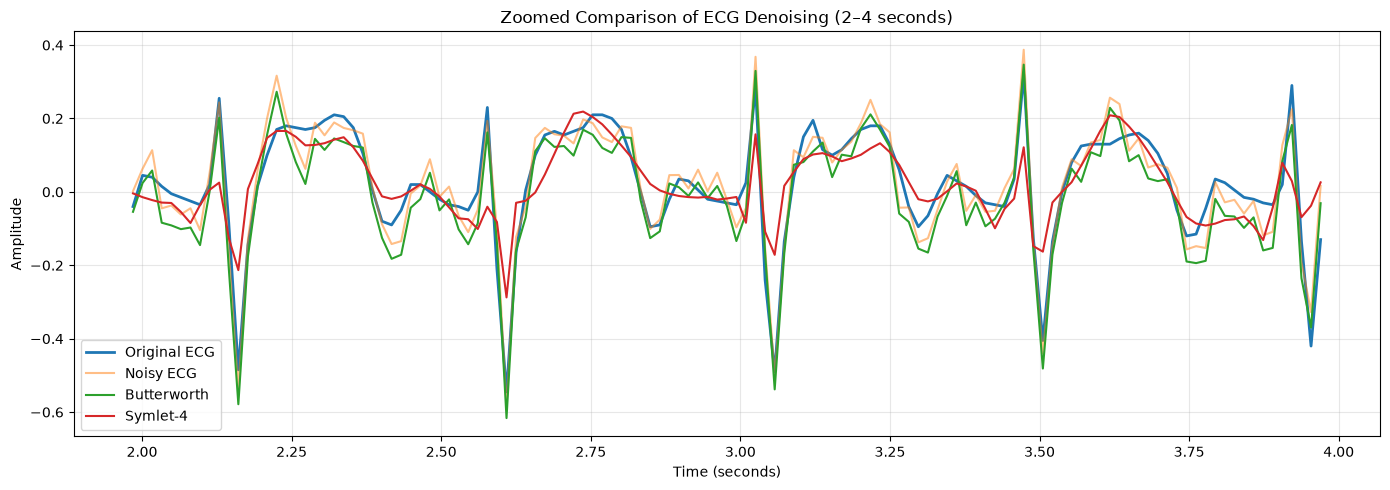

In [105]:
# Step 19: Zoomed-in ECG comparison

import matplotlib.pyplot as plt
import numpy as np

start_time = 2.0
end_time = 4.0

start_idx = int(start_time * fs)
end_idx = int(end_time * fs)

plt.figure(figsize=(14, 5))

plt.plot(
    time[start_idx:end_idx],
    reference[start_idx:end_idx],
    label="Original ECG",
    linewidth=2
)

plt.plot(
    time[start_idx:end_idx],
    noisy_signal[start_idx:end_idx],
    label="Noisy ECG",
    alpha=0.5
)

plt.plot(
    time[start_idx:end_idx],
    butterworth_output[start_idx:end_idx],
    label="Butterworth",
    linewidth=1.5
)

plt.plot(
    time[start_idx:end_idx],
    sym4_output[start_idx:end_idx],
    label="Symlet-4",
    linewidth=1.5
)

plt.title("Zoomed Comparison of ECG Denoising (2–4 seconds)")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [106]:
# Step 20: SNR improvement for Butterworth vs Symlet-4

import numpy as np
import pandas as pd
from scipy.signal import butter, sosfiltfilt
import pywt

snr_results = []

for record_id, signals in loaded_records.items():

    reference = np.asarray(signals["ecg"], dtype=float)
    fs = signals["fs"]

    # Recreate the same controlled Gaussian noise
    rng = np.random.default_rng(42)

    signal_power = np.mean(reference ** 2)
    noise_power = signal_power / (10 ** (10 / 10))

    noise = rng.normal(
        0,
        np.sqrt(noise_power),
        size=len(reference)
    )

    noisy_signal = reference + noise

    def calculate_snr(reference_signal, test_signal):
        error = reference_signal - test_signal
        error_power = np.mean(error ** 2)
        ref_power = np.mean(reference_signal ** 2)

        if error_power <= 0:
            return np.inf

        return 10 * np.log10(ref_power / error_power)

    input_snr = calculate_snr(reference, noisy_signal)

    # Butterworth
    sos = butter(
        4, [0.5, 30],
        btype="bandpass",
        fs=fs,
        output="sos"
    )

    butterworth_output = sosfiltfilt(sos, noisy_signal)

    # Symlet-4
    coeffs = pywt.wavedec(noisy_signal, "sym4", level=3)

    sigma = np.median(np.abs(coeffs[-1])) / 0.6745
    threshold = sigma * np.sqrt(2 * np.log(len(noisy_signal)))

    denoised_coeffs = [coeffs[0]]

    for detail in coeffs[1:]:
        denoised_coeffs.append(
            pywt.threshold(detail, threshold, mode="soft")
        )

    sym4_output = pywt.waverec(
        denoised_coeffs, "sym4"
    )[:len(reference)]

    for method, output in [
        ("Butterworth", butterworth_output),
        ("Symlet-4", sym4_output)
    ]:

        output_snr = calculate_snr(reference, output)

        snr_results.append({
            "Record_ID": record_id,
            "Method": method,
            "Input_SNR_dB": input_snr,
            "Output_SNR_dB": output_snr,
            "SNR_Improvement_dB": output_snr - input_snr
        })

snr_df = pd.DataFrame(snr_results)

display(snr_df.round(3))

print("\nAverage SNR performance:")
display(
    snr_df.groupby("Method")[
        ["Input_SNR_dB", "Output_SNR_dB", "SNR_Improvement_dB"]
    ].mean().round(3)
)

,Record_ID,Method,Input_SNR_dB,Output_SNR_dB,SNR_Improvement_dB
0,81739927_0008,Butterworth,10.363,2.641,-7.722
1,81739927_0008,Symlet-4,10.363,4.851,-5.512
2,81739927_0010,Butterworth,10.363,8.641,-1.722
3,81739927_0010,Symlet-4,10.363,5.958,-4.405
4,81739927_0014,Butterworth,10.363,9.617,-0.746
5,81739927_0014,Symlet-4,10.363,14.740,4.377
6,81739927_0016,Butterworth,10.363,6.395,-3.968
7,81739927_0016,Symlet-4,10.363,7.490,-2.873
8,81739927_0017,Butterworth,10.363,9.592,-0.771
9,81739927_0017,Symlet-4,10.363,8.709,-1.654



Average SNR performance:


,Input_SNR_dB,Output_SNR_dB,SNR_Improvement_dB
Method,,,
Butterworth,10.363,6.150,-4.213
Symlet-4,10.363,7.891,-2.472


In [107]:
import numpy as np

# Verify the input SNR for the selected ECG
record_id = "81739927_0008"

reference = np.asarray(
    loaded_records[record_id]["ecg"],
    dtype=float
)

fs = loaded_records[record_id]["fs"]

rng = np.random.default_rng(42)

signal_power = np.mean(reference ** 2)
noise_power = signal_power / (10 ** (10 / 10))

noise = rng.normal(
    0,
    np.sqrt(noise_power),
    size=len(reference)
)

noisy_signal = reference + noise

measured_input_snr = 10 * np.log10(
    np.mean(reference ** 2) / np.mean(noise ** 2)
)

print(f"Target SNR: 10.000 dB")
print(f"Measured input SNR: {measured_input_snr:.3f} dB")

Target SNR: 10.000 dB
Measured input SNR: 10.363 dB


In [108]:
import numpy as np
import pandas as pd
import pywt
from scipy.signal import butter, sosfiltfilt

verified_snr_results = []

for record_id, signals in loaded_records.items():

    reference = np.asarray(signals["ecg"], dtype=float)
    fs = signals["fs"]

    # Recreate the controlled noise
    rng = np.random.default_rng(42)

    signal_power = np.mean(reference ** 2)
    noise_power = signal_power / (10 ** (10 / 10))

    noise = rng.normal(
        0,
        np.sqrt(noise_power),
        size=len(reference)
    )

    noisy_signal = reference + noise

    # Input SNR: reference compared with the actual added noise
    input_snr = 10 * np.log10(
        np.mean(reference ** 2) / np.mean(noise ** 2)
    )

    # Butterworth filtering
    sos = butter(
        4, [0.5, 30],
        btype="bandpass",
        fs=fs,
        output="sos"
    )

    butterworth_output = sosfiltfilt(sos, noisy_signal)

    # Symlet-4 wavelet denoising
    coeffs = pywt.wavedec(noisy_signal, "sym4", level=3)

    sigma = np.median(np.abs(coeffs[-1])) / 0.6745
    threshold = sigma * np.sqrt(2 * np.log(len(noisy_signal)))

    denoised_coeffs = [coeffs[0]]

    for detail in coeffs[1:]:
        denoised_coeffs.append(
            pywt.threshold(detail, threshold, mode="soft")
        )

    sym4_output = pywt.waverec(
        denoised_coeffs, "sym4"
    )[:len(reference)]

    # Evaluate each method against the same reference
    for method, output in [
        ("Butterworth", butterworth_output),
        ("Symlet-4", sym4_output)
    ]:

        error_power = np.mean((reference - output) ** 2)

        output_snr = (
            10 * np.log10(signal_power / error_power)
            if error_power > 0 else np.inf
        )

        verified_snr_results.append({
            "Record_ID": record_id,
            "Method": method,
            "Input_SNR_dB": input_snr,
            "Output_SNR_dB": output_snr,
            "SNR_Improvement_dB": output_snr - input_snr
        })

verified_snr_df = pd.DataFrame(verified_snr_results)

display(verified_snr_df.round(3))

print("\nAverage SNR results across 10 records:")

display(
    verified_snr_df.groupby("Method")[
        ["Input_SNR_dB", "Output_SNR_dB", "SNR_Improvement_dB"]
    ].mean().round(3)
)

,Record_ID,Method,Input_SNR_dB,Output_SNR_dB,SNR_Improvement_dB
0,81739927_0008,Butterworth,10.363,2.641,-7.722
1,81739927_0008,Symlet-4,10.363,4.851,-5.512
2,81739927_0010,Butterworth,10.363,8.641,-1.722
3,81739927_0010,Symlet-4,10.363,5.958,-4.405
4,81739927_0014,Butterworth,10.363,9.617,-0.746
5,81739927_0014,Symlet-4,10.363,14.740,4.377
6,81739927_0016,Butterworth,10.363,6.395,-3.968
7,81739927_0016,Symlet-4,10.363,7.490,-2.873
8,81739927_0017,Butterworth,10.363,9.592,-0.771
9,81739927_0017,Symlet-4,10.363,8.709,-1.654



Average SNR results across 10 records:


,Input_SNR_dB,Output_SNR_dB,SNR_Improvement_dB
Method,,,
Butterworth,10.363,6.150,-4.213
Symlet-4,10.363,7.891,-2.472


In [109]:
import numpy as np
import pandas as pd

input_snr_check = []

for record_id, signals in loaded_records.items():

    reference = np.asarray(signals["ecg"], dtype=float)

    rng = np.random.default_rng(42)

    signal_power = np.mean(reference ** 2)
    noise_power = signal_power / (10 ** (10 / 10))

    noise = rng.normal(
        0,
        np.sqrt(noise_power),
        size=len(reference)
    )

    measured_snr = 10 * np.log10(
        np.mean(reference ** 2) / np.mean(noise ** 2)
    )

    input_snr_check.append({
        "Record_ID": record_id,
        "Signal_Power": signal_power,
        "Noise_Power_Target": noise_power,
        "Measured_Input_SNR_dB": measured_snr
    })

input_snr_check_df = pd.DataFrame(input_snr_check)

display(input_snr_check_df.round(4))

,Record_ID,Signal_Power,Noise_Power_Target,Measured_Input_SNR_dB
0,81739927_0008,0.0253,0.0025,10.3631
1,81739927_0010,0.0119,0.0012,10.3631
2,81739927_0014,15.1078,1.5108,10.3631
3,81739927_0016,0.0166,0.0017,10.3631
4,81739927_0017,0.0270,0.0027,10.3631
5,81739927_0020,0.0410,0.0041,10.3631
6,87033314_0007,0.0145,0.0015,10.3631
7,87033314_0008,0.0115,0.0012,10.3631
8,83404654_0001,0.0583,0.0058,10.3631
9,83404654_0004,0.0102,0.0010,10.3631
